# Rough workflow
1. Import of data
2. Cleaning the data and updating it in file 
3. Reading and learning patterns in data
4. Transforming the data accordingly if necessary 
5. Removal of outliners if present in data
6. Adding dummy variables for categorical features 
7. Scaling features 
8. Fit the linear regression model 
9. Postprocessing

In [52]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import seaborn as sns
import scipy.stats as stats

### 1. Importing the data

In [53]:
housing_data = pd.read_csv('kc_house_data.csv')
housing_data

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


### 2. Cleaning the data 

In [54]:
# Removing id, date, sqft_living15, sqft_lot15
housing_data.drop(['id', 'date', 'sqft_living15', 'sqft_lot15'], axis = 1, inplace= True)

In [55]:
# exporting the dataframe
housing_data.to_csv('updated_housing_data')

In [56]:
# checking for the missing data
housing_data.isna().sum()

price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
dtype: int64

### 3. Reading data and finding the patterns in data

In [57]:
housing_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          21613 non-null  float64
 1   bedrooms       21613 non-null  int64  
 2   bathrooms      21613 non-null  float64
 3   sqft_living    21613 non-null  int64  
 4   sqft_lot       21613 non-null  int64  
 5   floors         21613 non-null  float64
 6   waterfront     21613 non-null  int64  
 7   view           21613 non-null  int64  
 8   condition      21613 non-null  int64  
 9   grade          21613 non-null  int64  
 10  sqft_above     21613 non-null  int64  
 11  sqft_basement  21613 non-null  int64  
 12  yr_built       21613 non-null  int64  
 13  yr_renovated   21613 non-null  int64  
 14  zipcode        21613 non-null  int64  
 15  lat            21613 non-null  float64
 16  long           21613 non-null  float64
dtypes: float64(5), int64(12)
memory usage: 2.8 MB


In [58]:
housing_data.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long
count,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896
std,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828
min,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000
25%,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000
50%,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000
75%,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000
max,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000


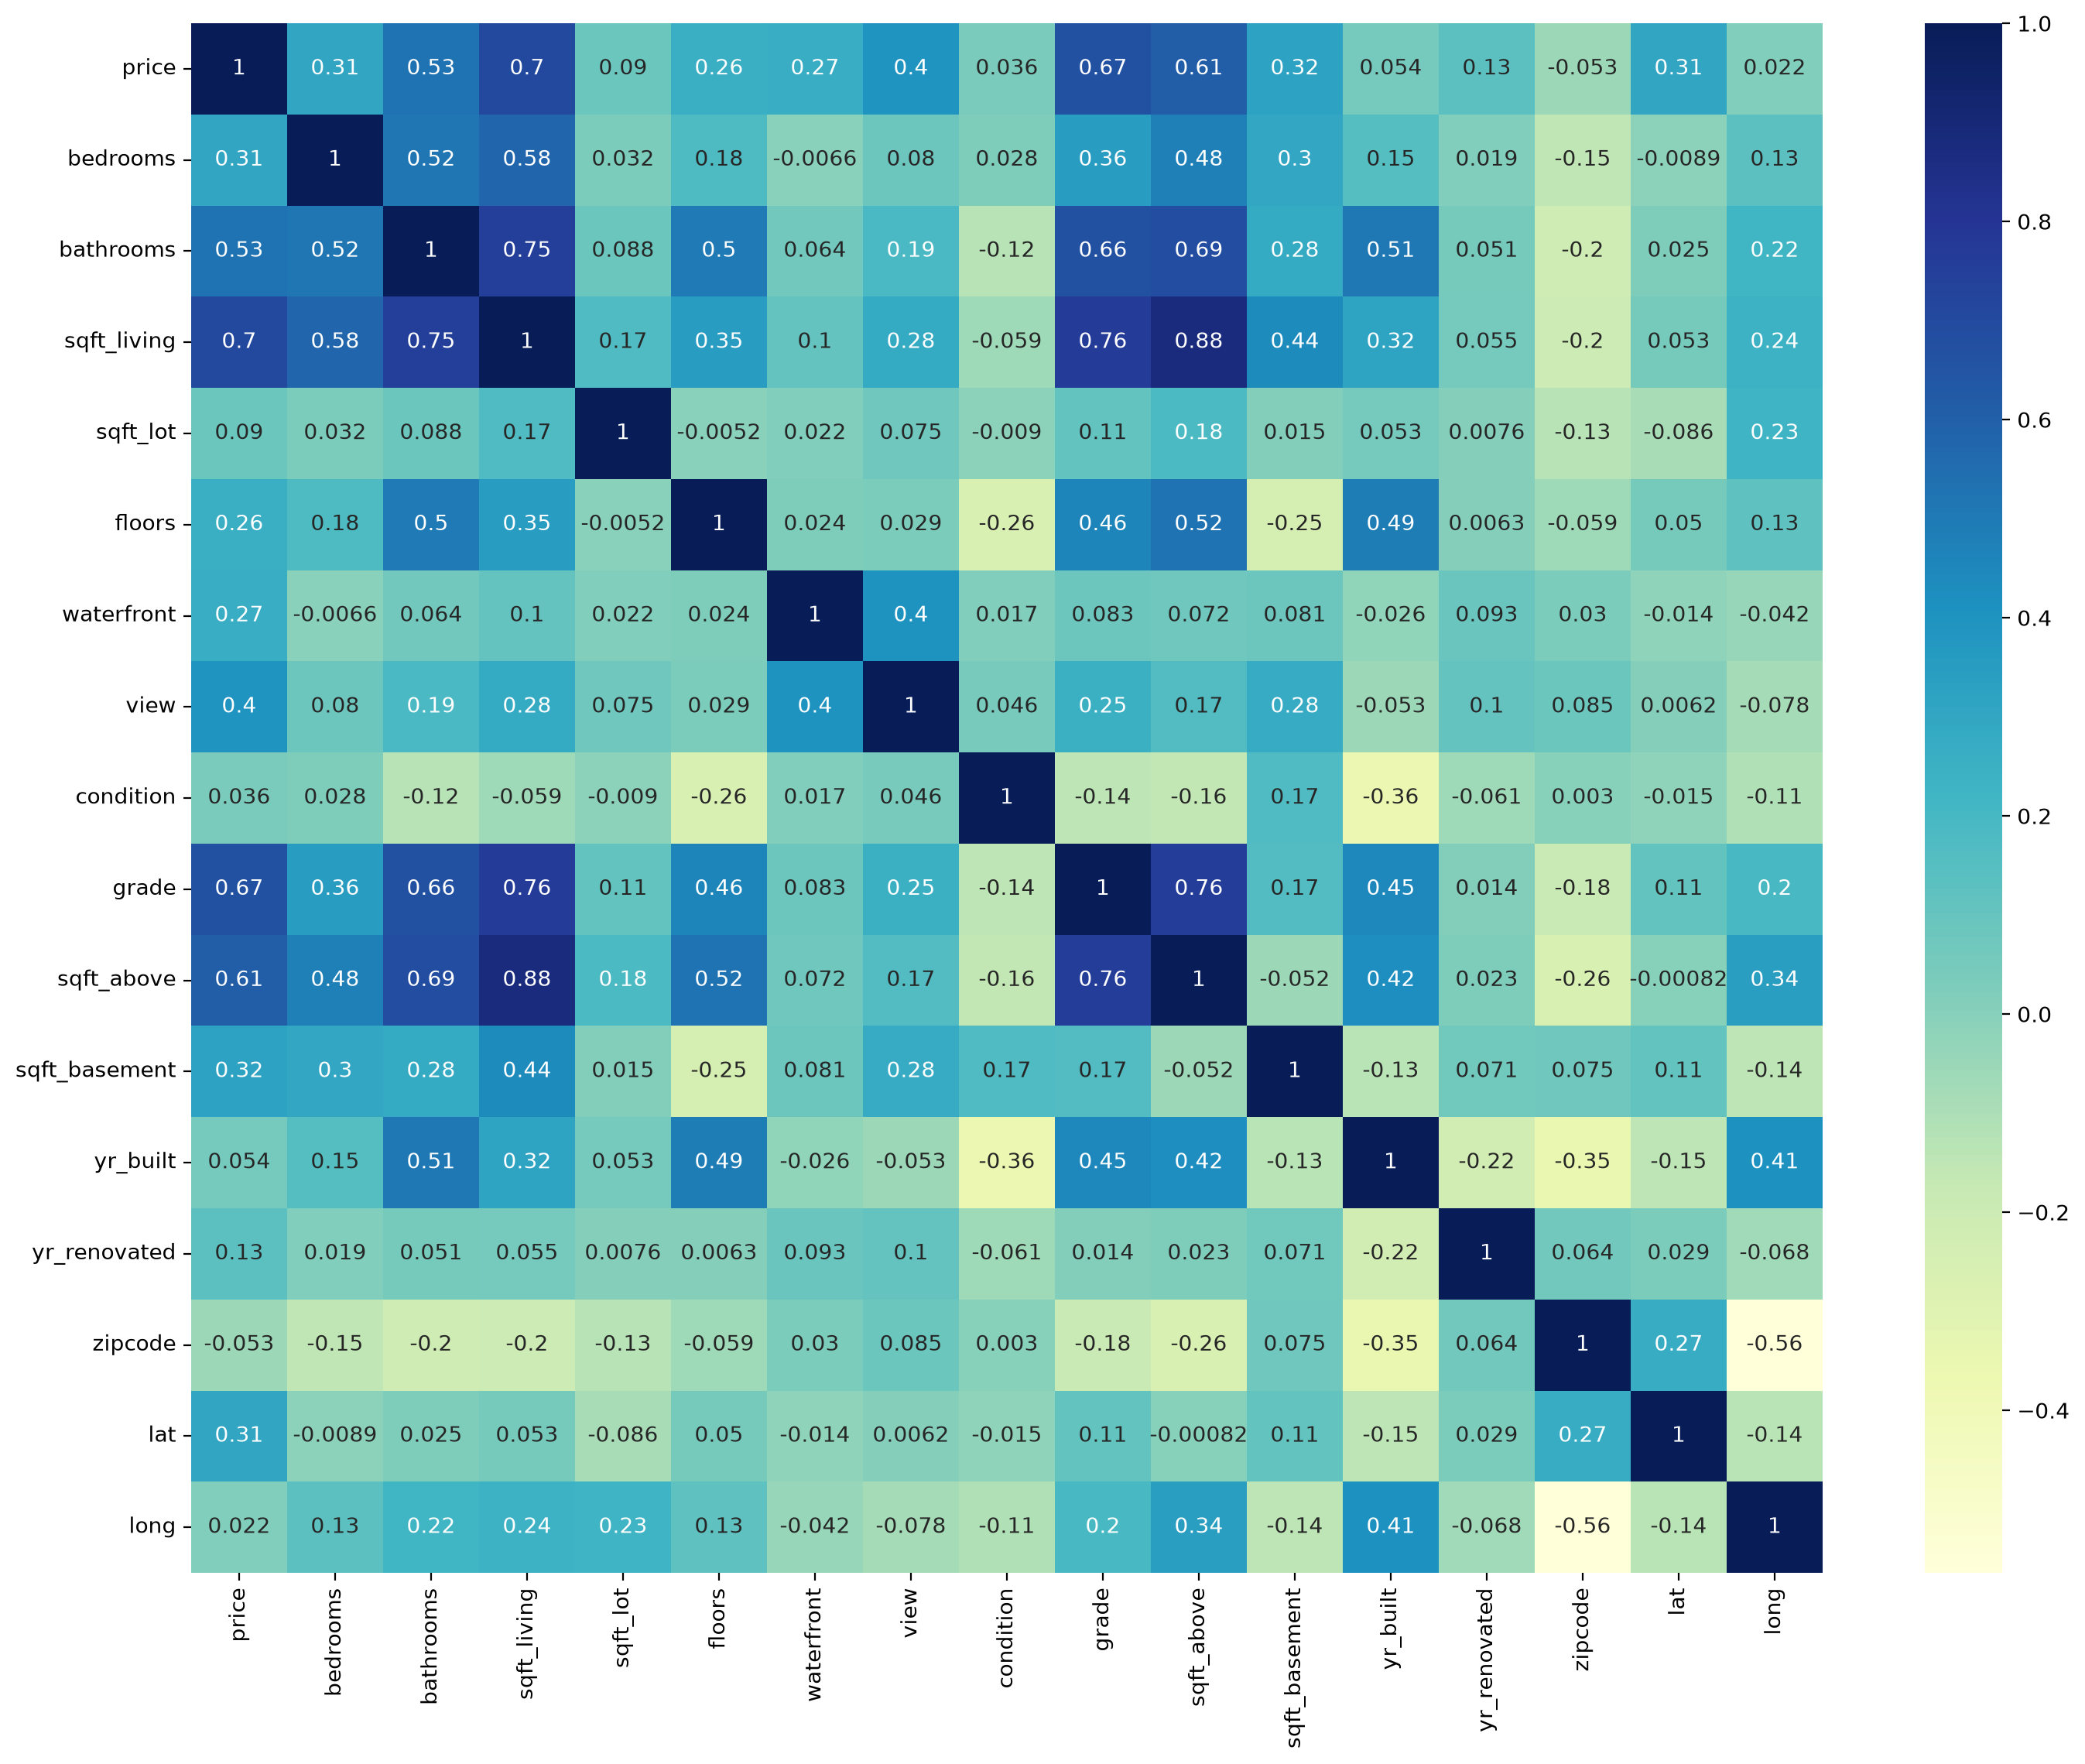

In [59]:
# checking for co-relation between the columns 
# method 1 : Chart
housing_data.corr()

# method 2 : Graphical representation
fig, ax = plt.subplots(figsize = (17,13))
ax = sns.heatmap(housing_data.corr(), annot = True , cmap = 'YlGnBu')


#### 3.1 Learing patterns in columns and marking the issue according to Linear Regression model

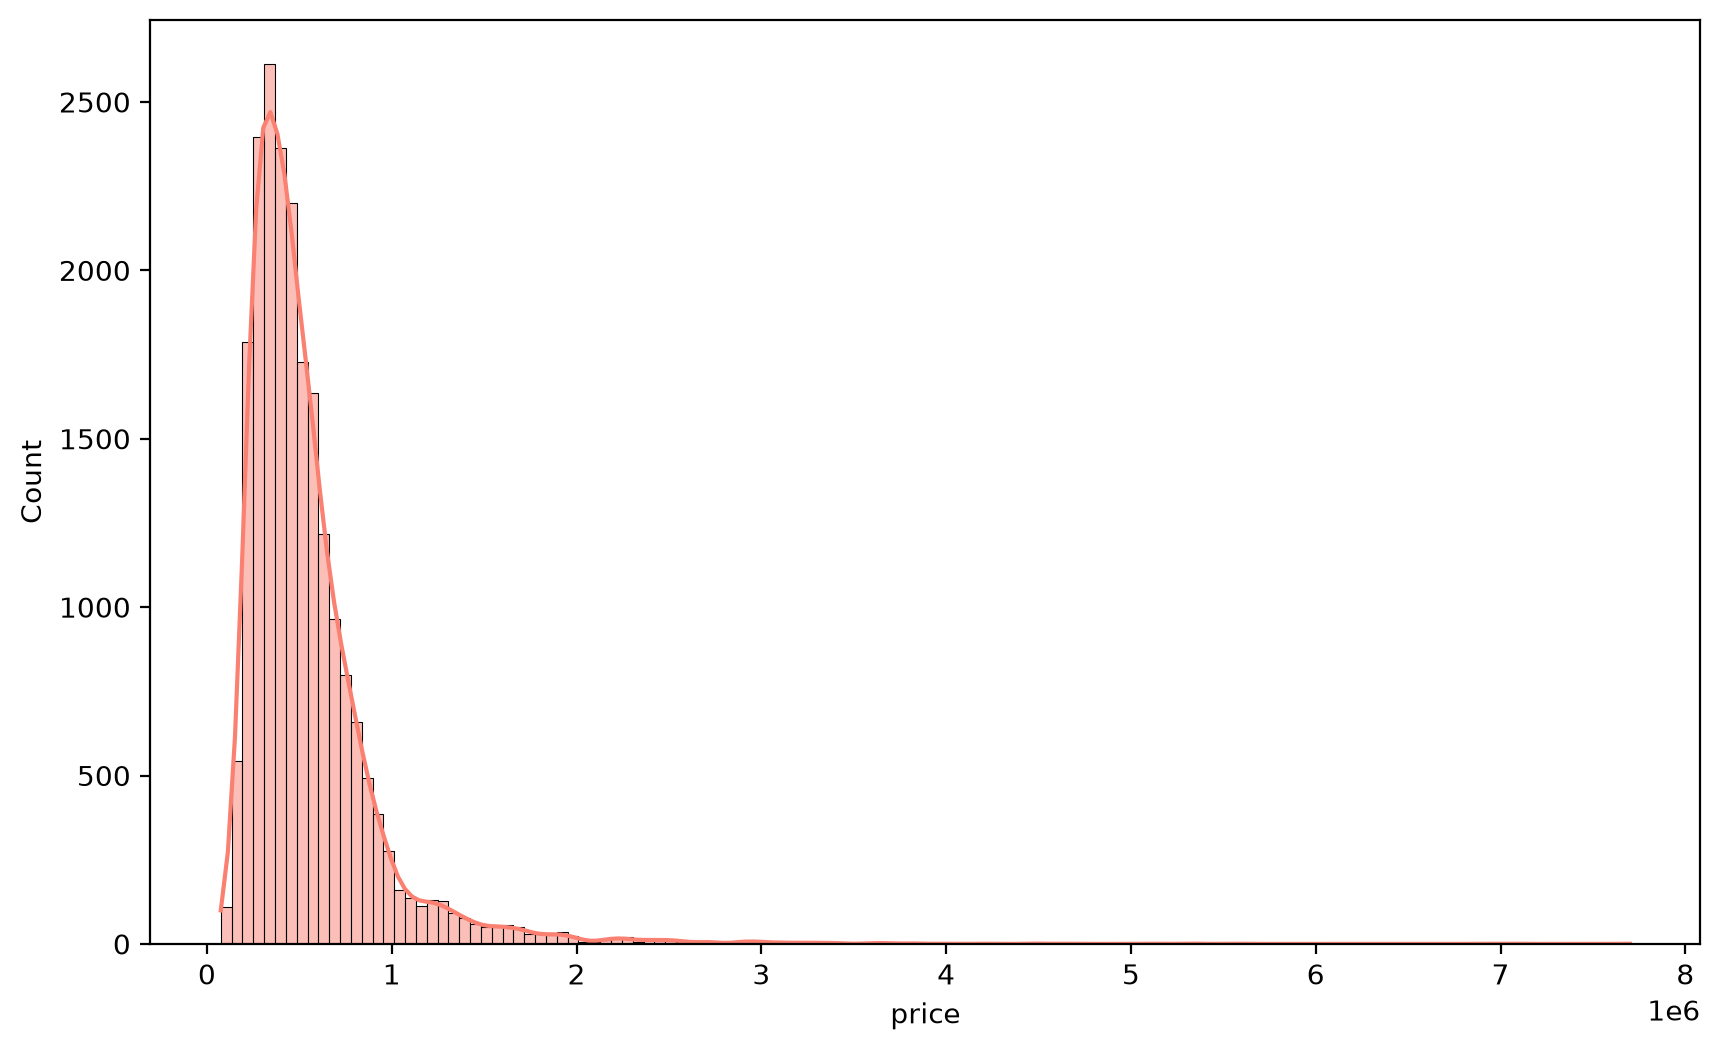

In [60]:
# Price
fig, ax = plt.subplots(figsize = (10,6))
sns.histplot(x = housing_data.price, color = 'salmon',
             kde = True,
             bins = 130            
            );

In [61]:
housing_data.price.describe()

count    2.161300e+04
mean     5.400881e+05
std      3.671272e+05
min      7.500000e+04
25%      3.219500e+05
50%      4.500000e+05
75%      6.450000e+05
max      7.700000e+06
Name: price, dtype: float64

In [62]:
one = (housing_data.price > 4e+06).sum()
one

np.int64(11)

Text(0.5, 1.0, 'QQ Plot')

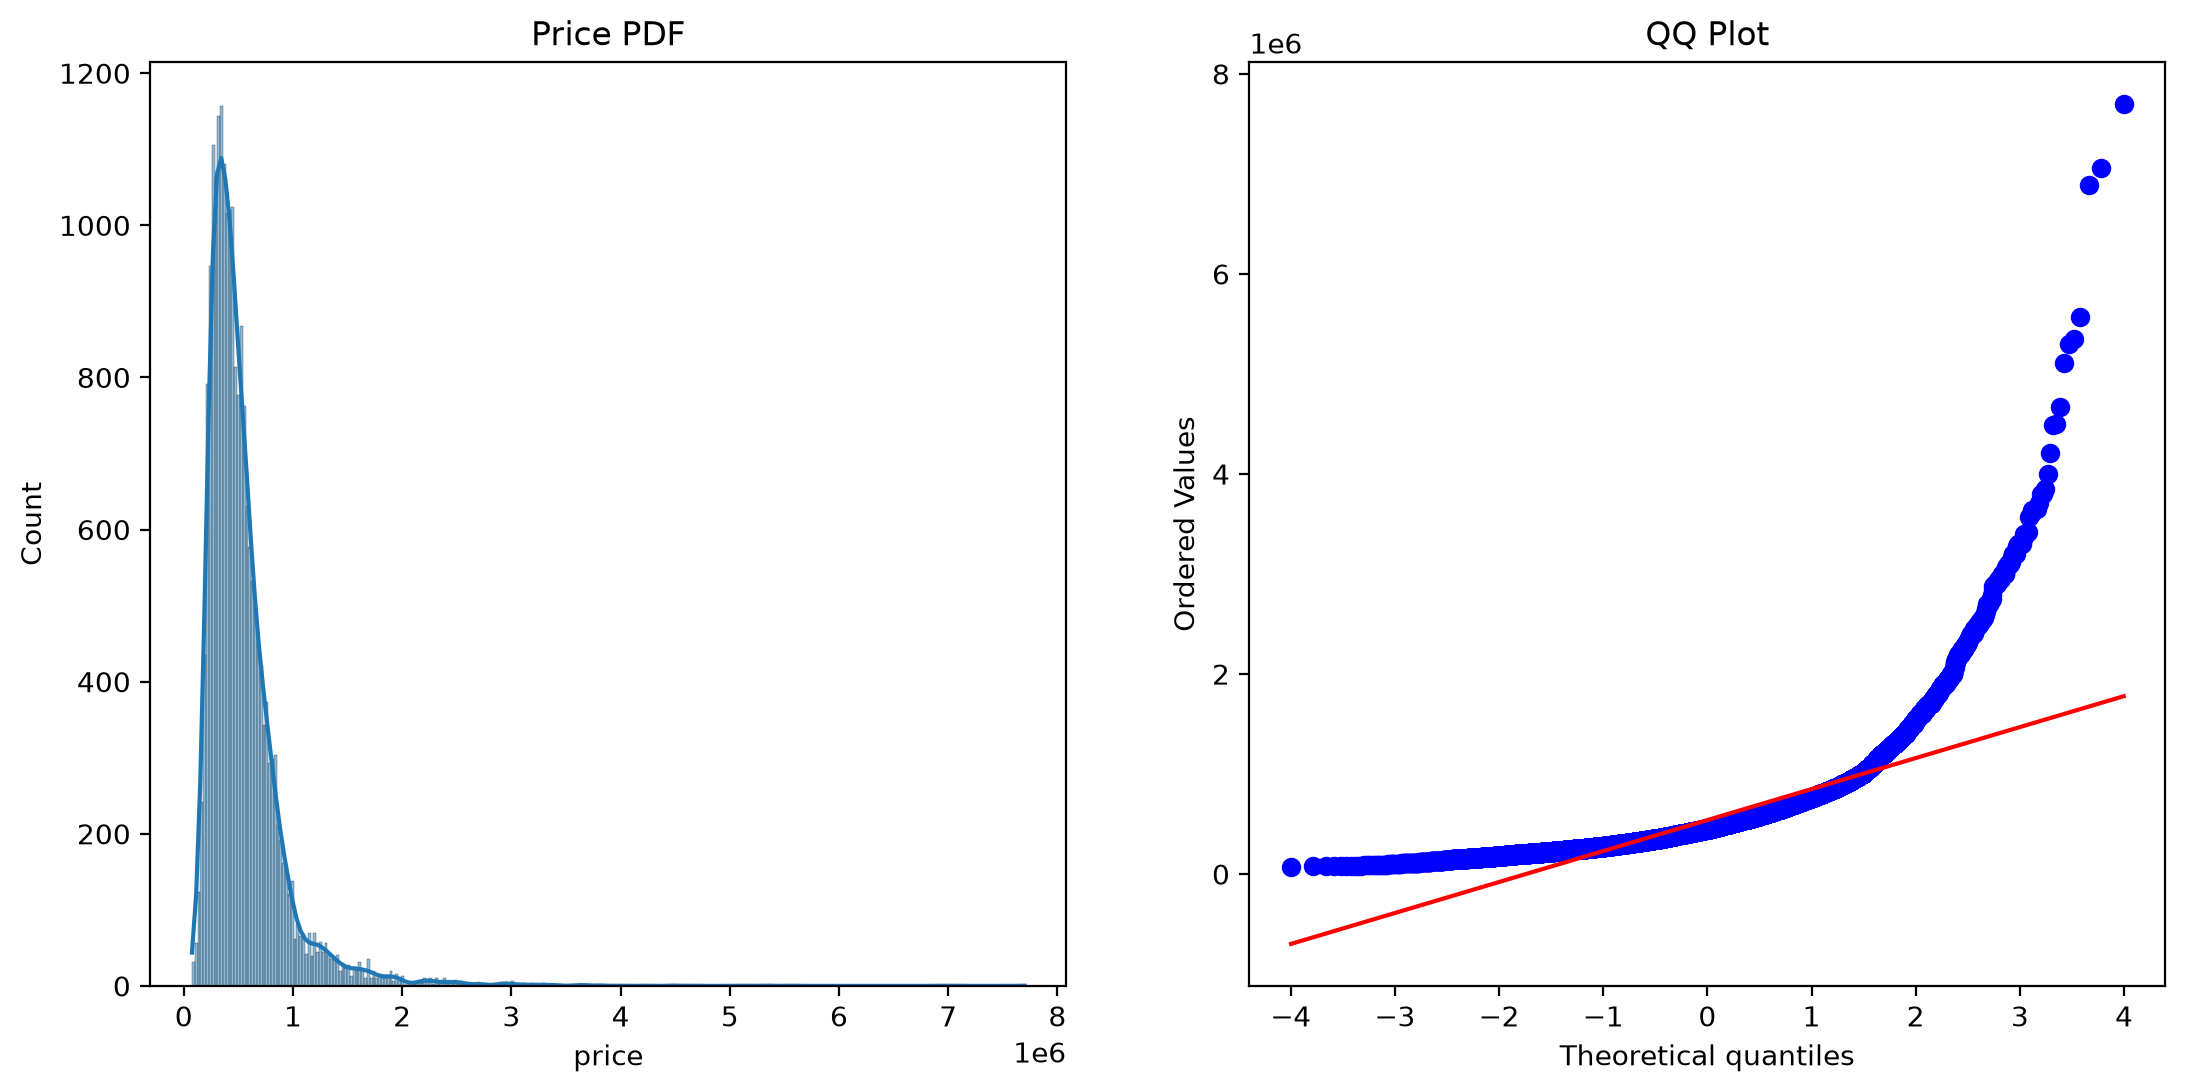

In [69]:
# Making QQ plot
fig, (ax0,ax1) = plt.subplots(figsize = (13,6), ncols= 2)
sns.histplot(housing_data.price, kde = True , ax = ax0)
ax0.set_title('Price PDF')

stats.probplot(housing_data.price, dist = 'norm', plot = ax1)
ax1.set_title('QQ Plot')

**The price is right skewed which we will have to remove outliers and transform it make it little bit normally distributed**

In [13]:
# bedrooms
bed_info = housing_data.bedrooms.value_counts()
print(bed_info)

bedrooms
3     9824
4     6882
2     2760
5     1601
6      272
1      199
7       38
0       13
8       13
9        6
10       3
11       1
33       1
Name: count, dtype: int64


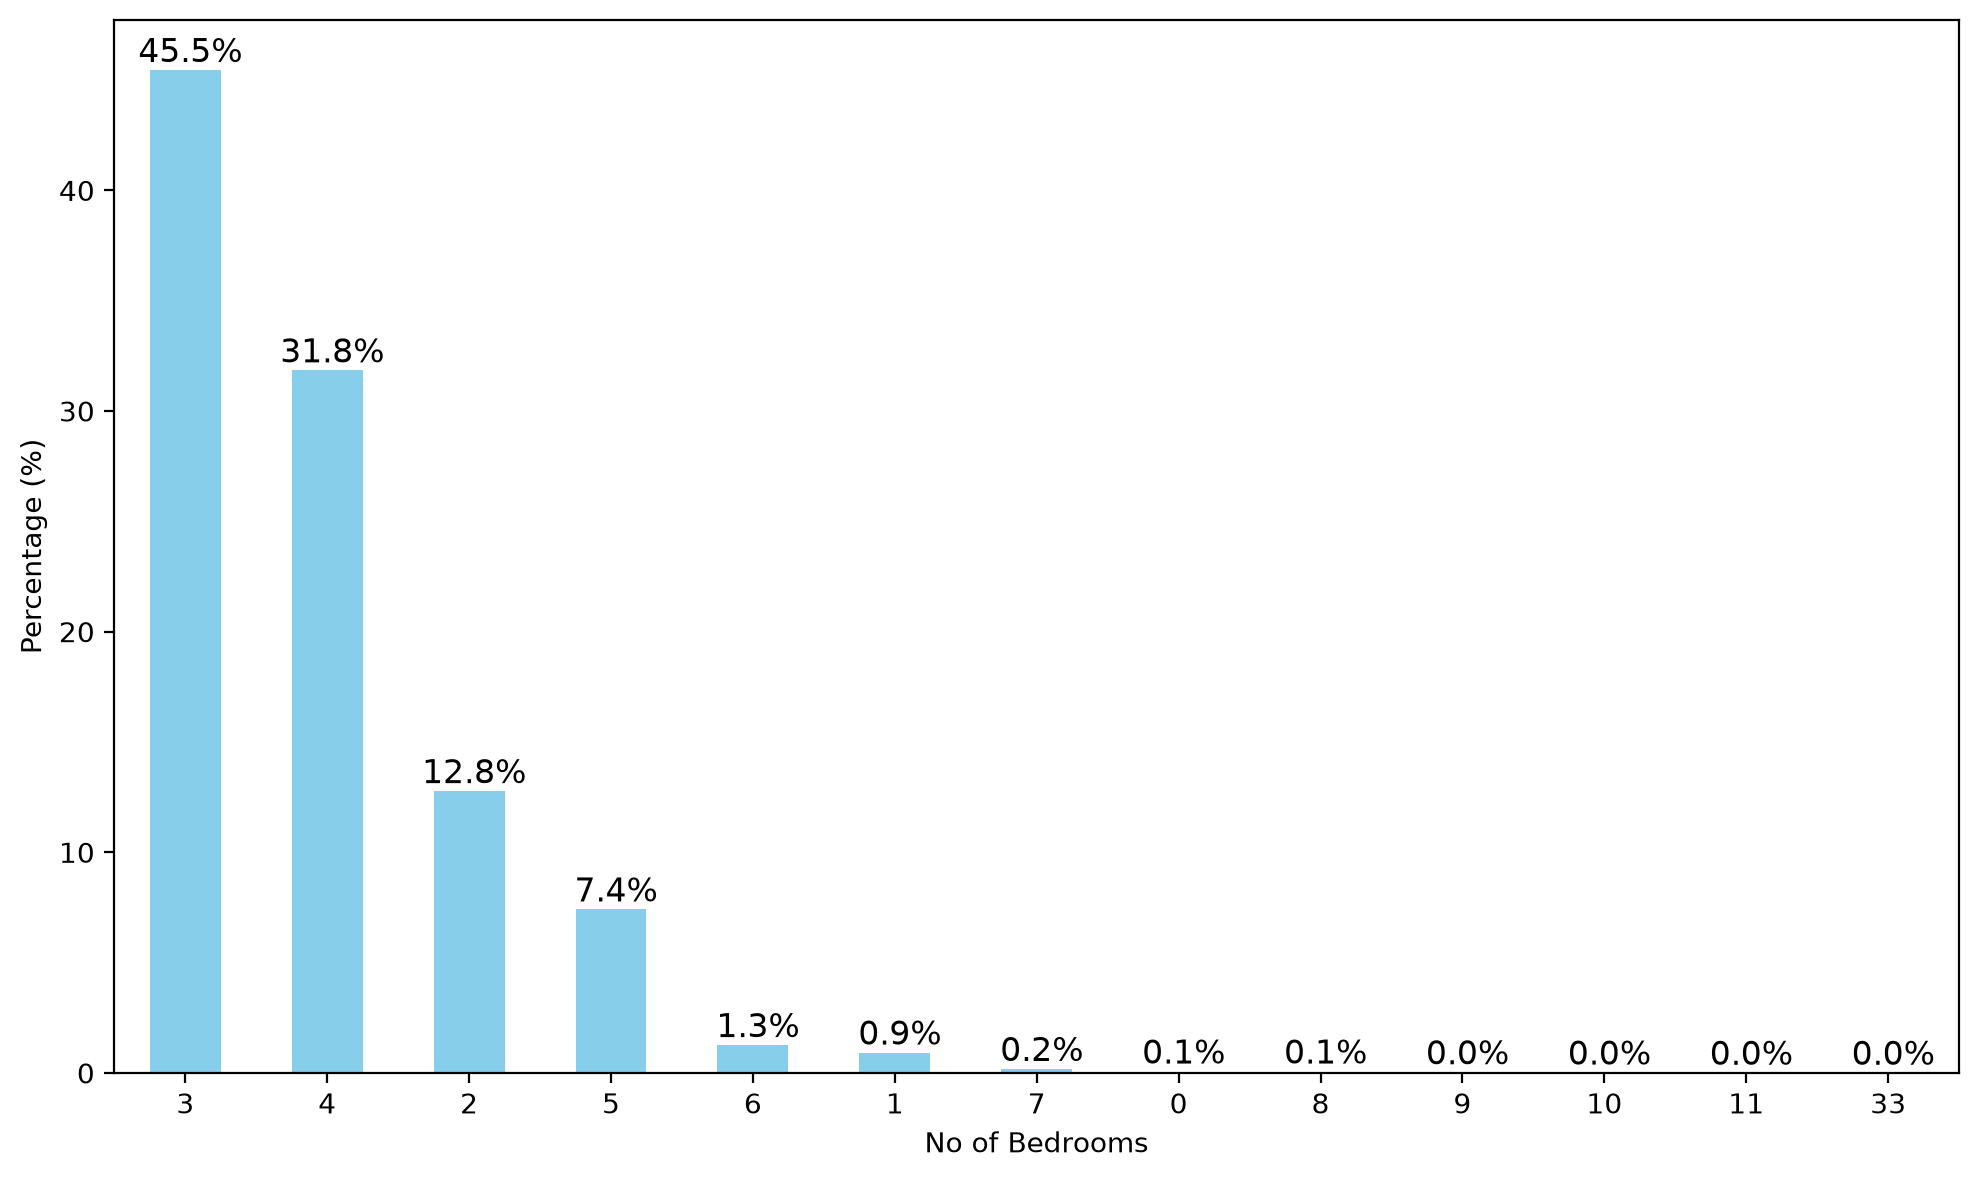

In [14]:
# computing percentages 
per = housing_data.bedrooms.value_counts(normalize= True) * 100

fig, ax = plt.subplots(figsize = (10,6))
per.plot(kind = 'bar', color = 'skyblue')

plt.ylabel('Percentage (%)')
plt.xlabel('No of Bedrooms')

# annotate each bar 
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height: .1f}%', 
               (p.get_x() + p.get_width()/2, height),
                ha = 'center', va = 'bottom', fontsize =12)
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

**We will have to check for this 33 rooms as it is a outlier is its price is as high as the no of rooms we will not remove it or else we have to remove it**

In [15]:
# bathrooms
housing_data.bathrooms.value_counts()

bathrooms
2.50    5380
1.00    3852
1.75    3048
2.25    2047
2.00    1930
1.50    1446
2.75    1185
3.00     753
3.50     731
3.25     589
3.75     155
4.00     136
4.50     100
4.25      79
0.75      72
4.75      23
5.00      21
5.25      13
0.00      10
5.50      10
1.25       9
6.00       6
0.50       4
5.75       4
6.75       2
8.00       2
6.25       2
6.50       2
7.50       1
7.75       1
Name: count, dtype: int64

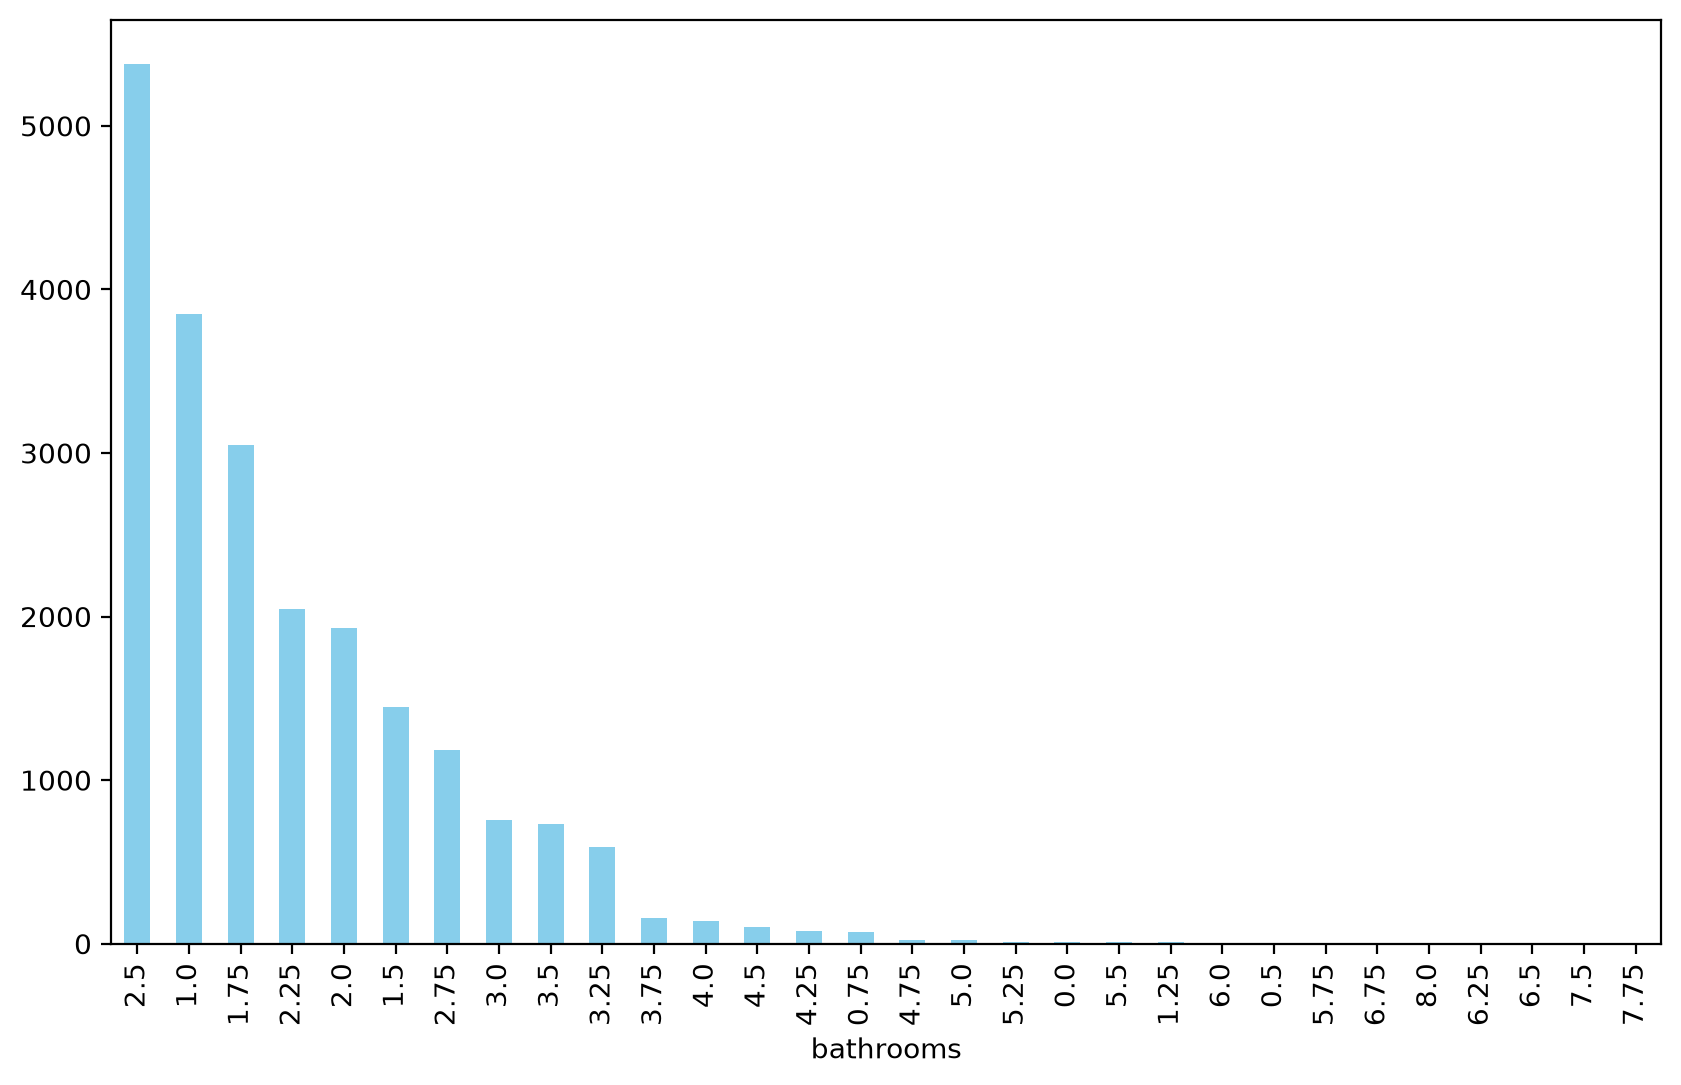

In [16]:
housing_data.bathrooms.value_counts().plot(kind = 'bar', color = 'skyblue', figsize = (10,6));

**for this we will be grouping all above 5 together as they are pretty small in quantity and giving our data partial outliers**

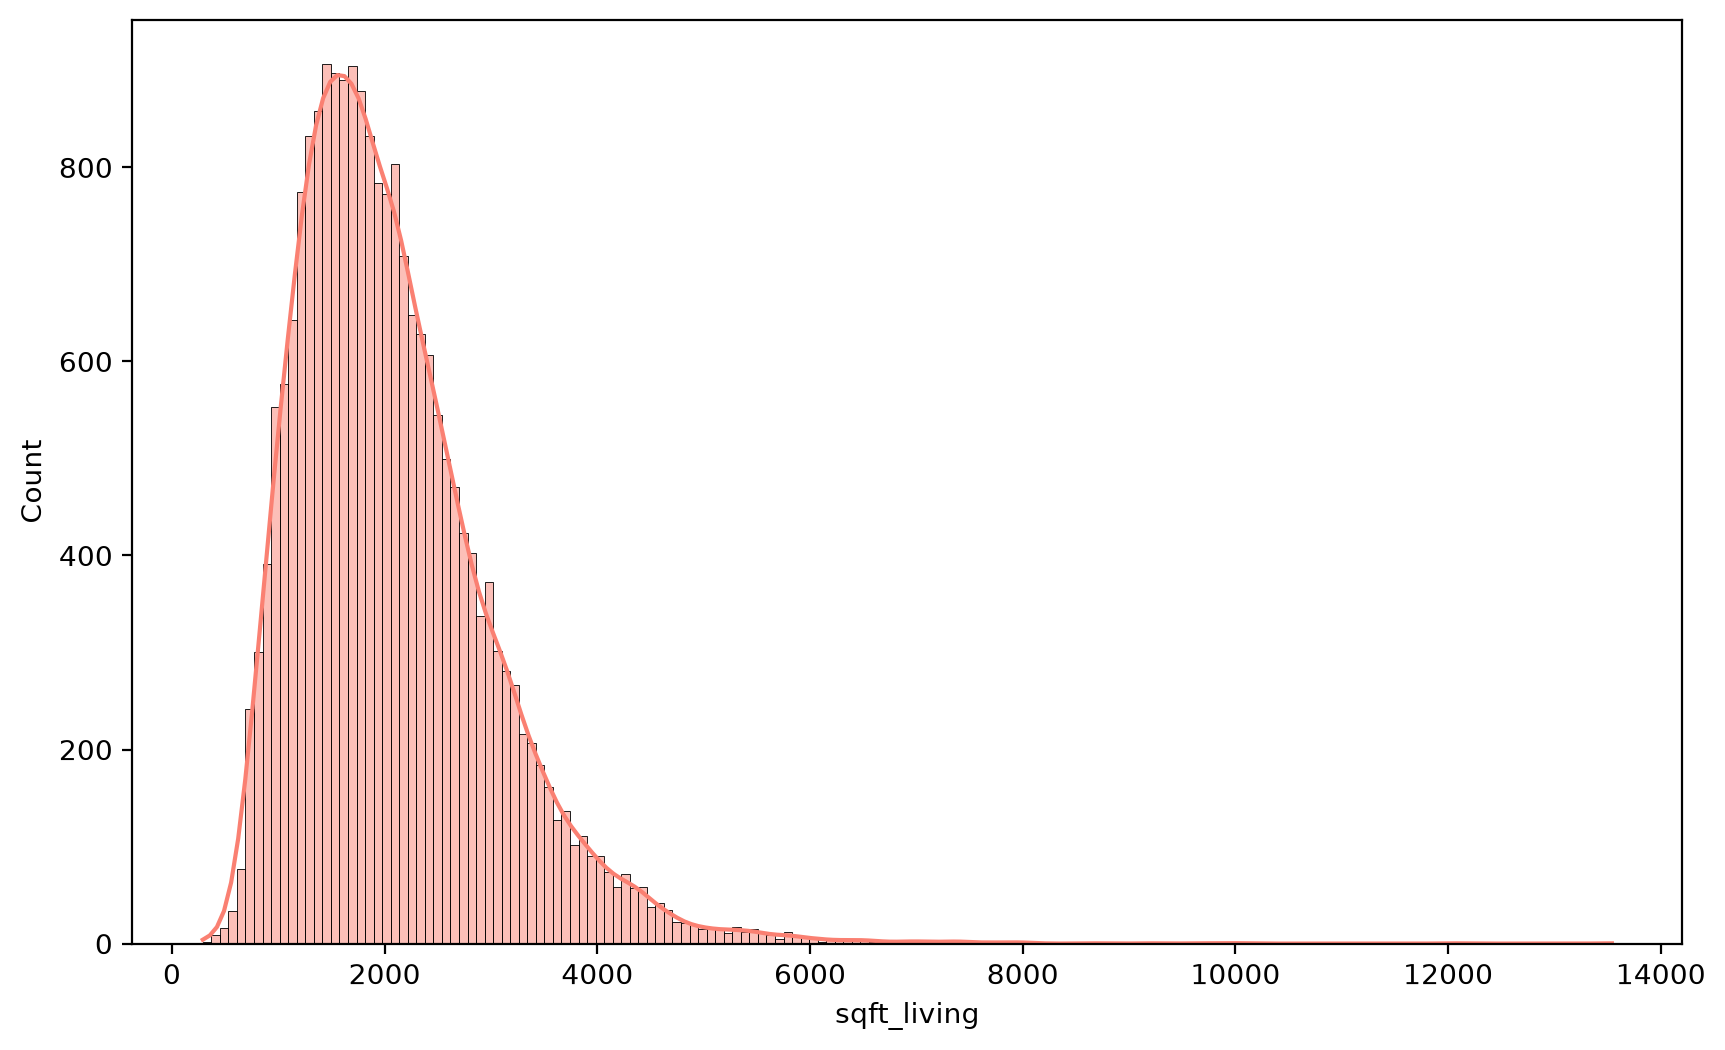

In [17]:
# Living area
fig, ax = plt.subplots(figsize = (10,6))
sns.histplot(housing_data.sqft_living, kde = True, color = 'salmon');

Text(0.5, 1.0, 'Probablity Plot (QQ Plot)')

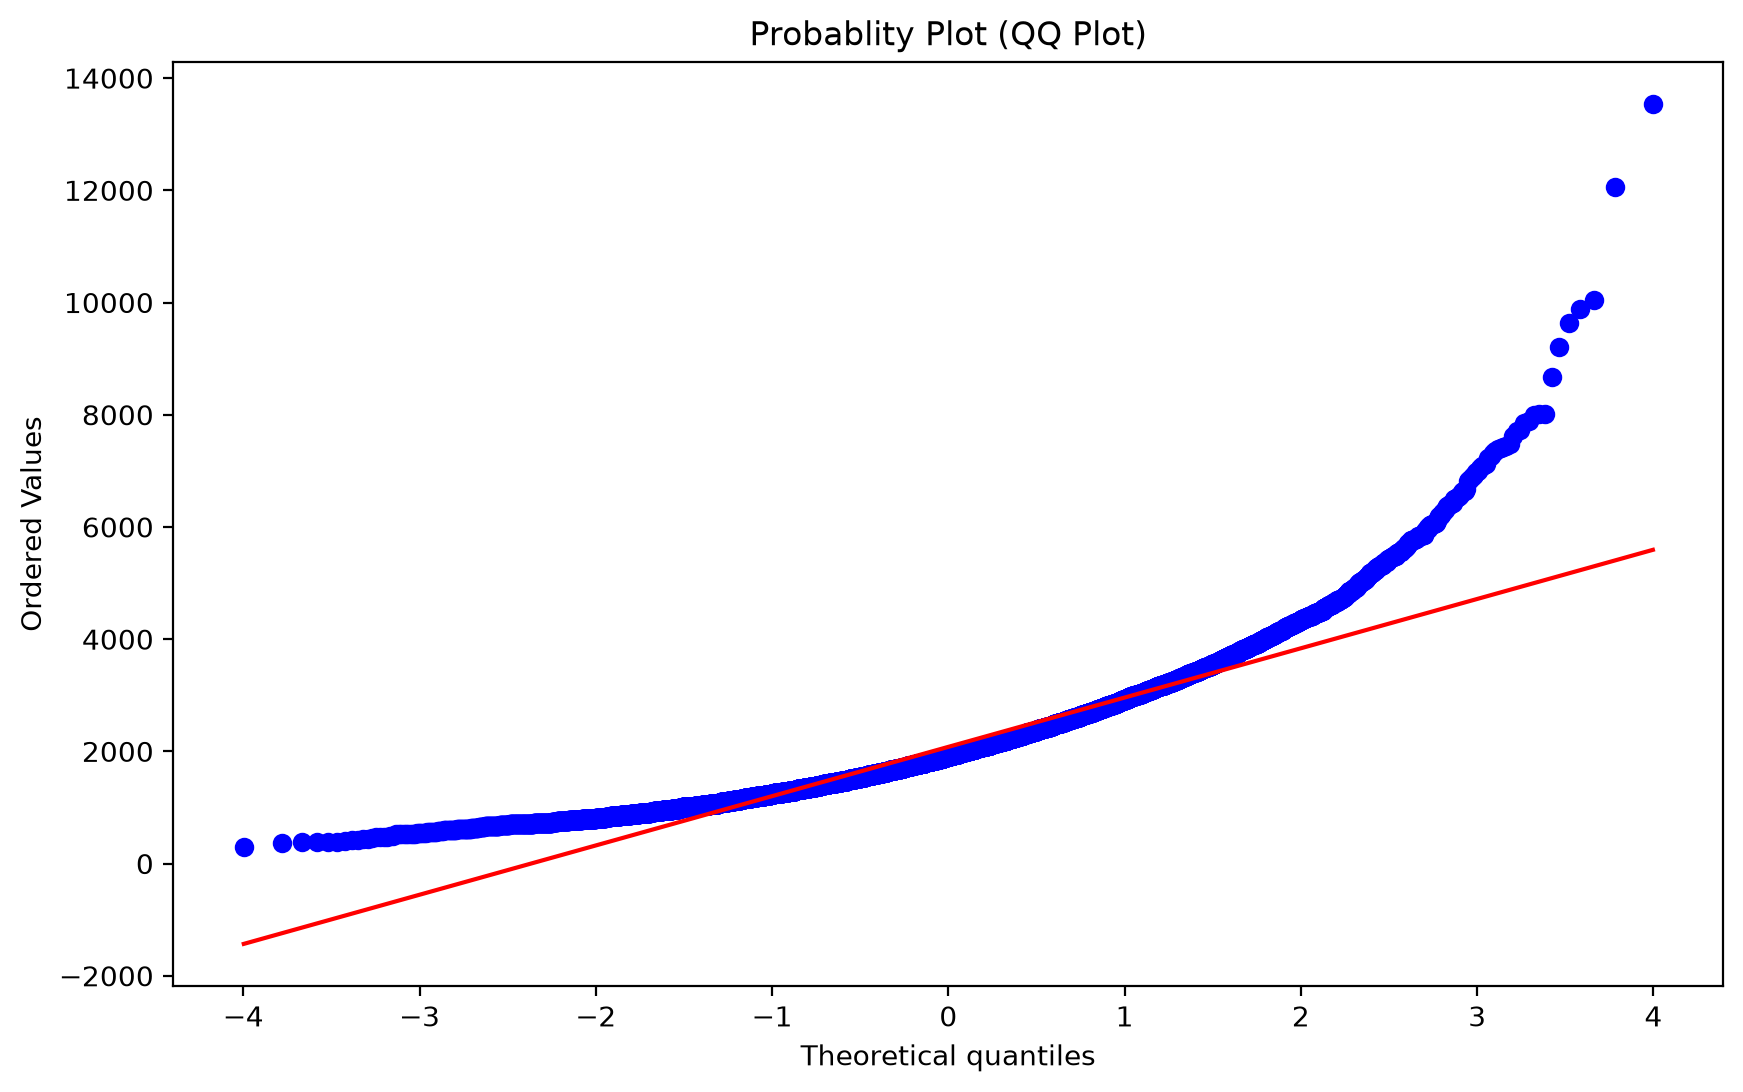

In [72]:
fig, ax = plt.subplots(figsize = (10,6))
stats.probplot(housing_data.sqft_living, dist = 'norm', plot = ax)
plt.title('Probablity Plot (QQ Plot)')

**The data is right skewed we will try making is as normally distributed as possible**

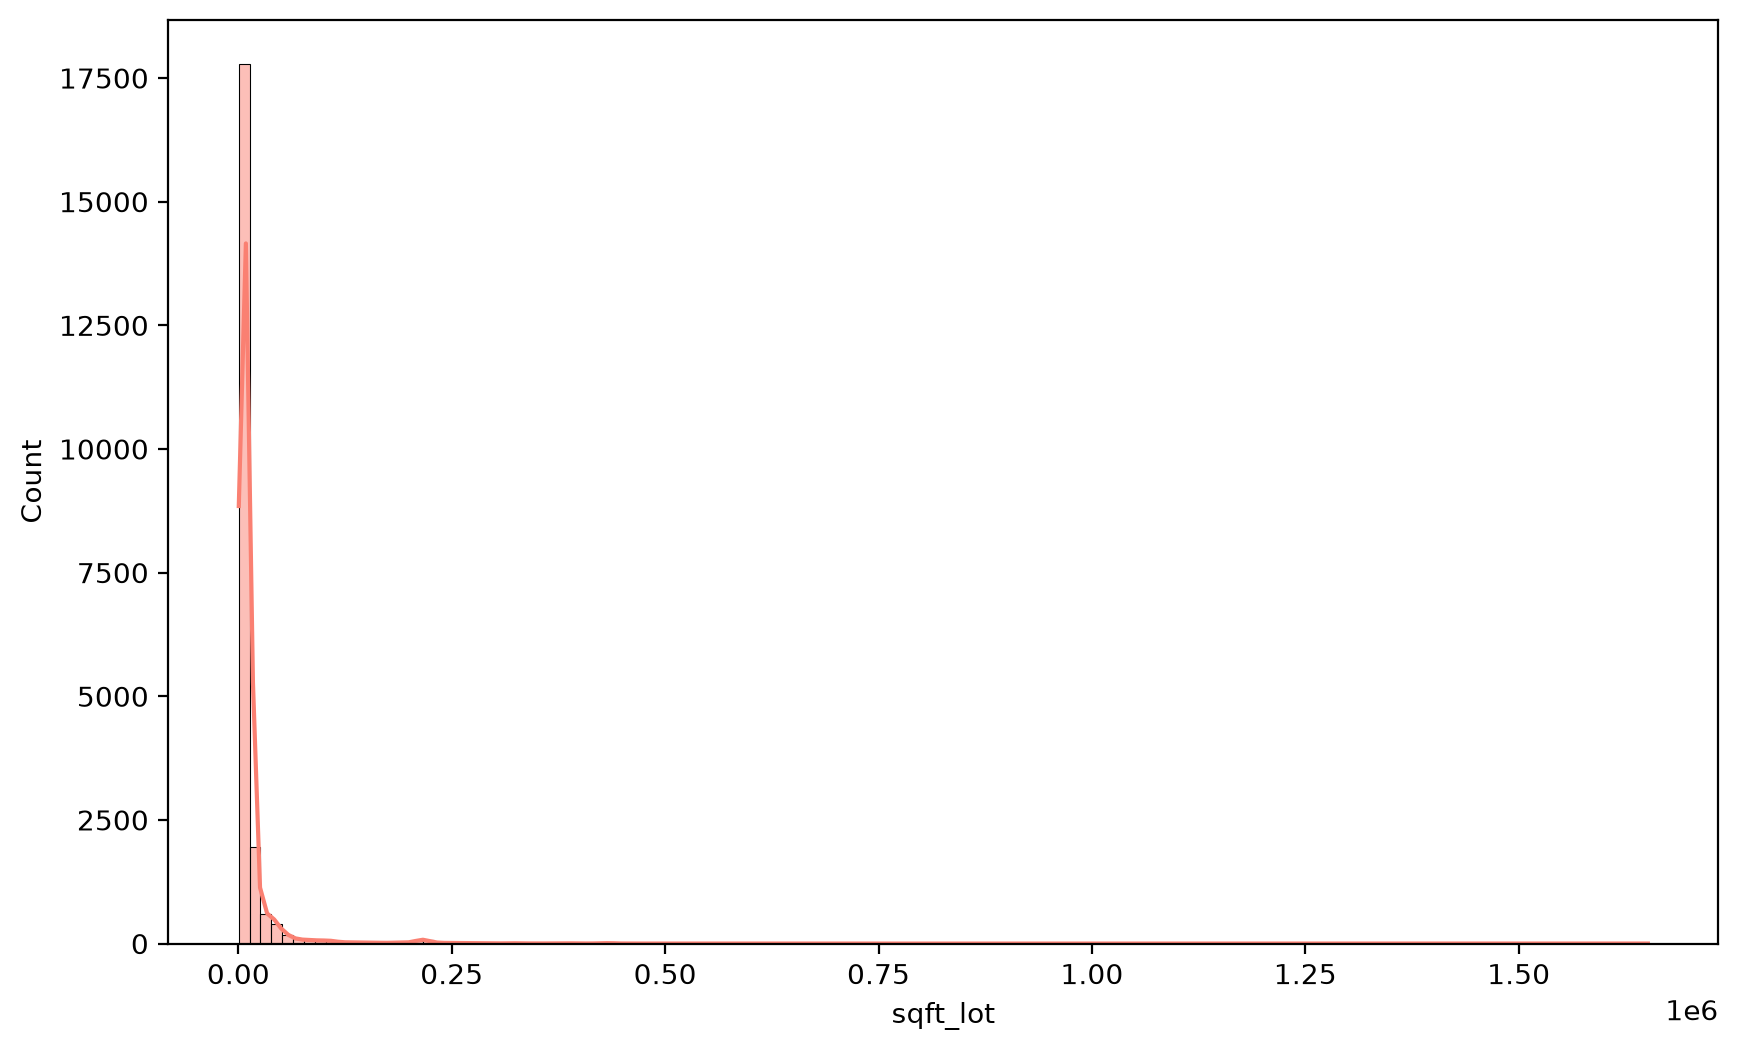

In [18]:
# Total Area
fig, ax = plt.subplots(figsize = (10,6))
sns.histplot(housing_data.sqft_lot, kde = True, color = 'salmon', bins = 130);

Text(0.5, 1.0, 'QQ Plot of Total Area')

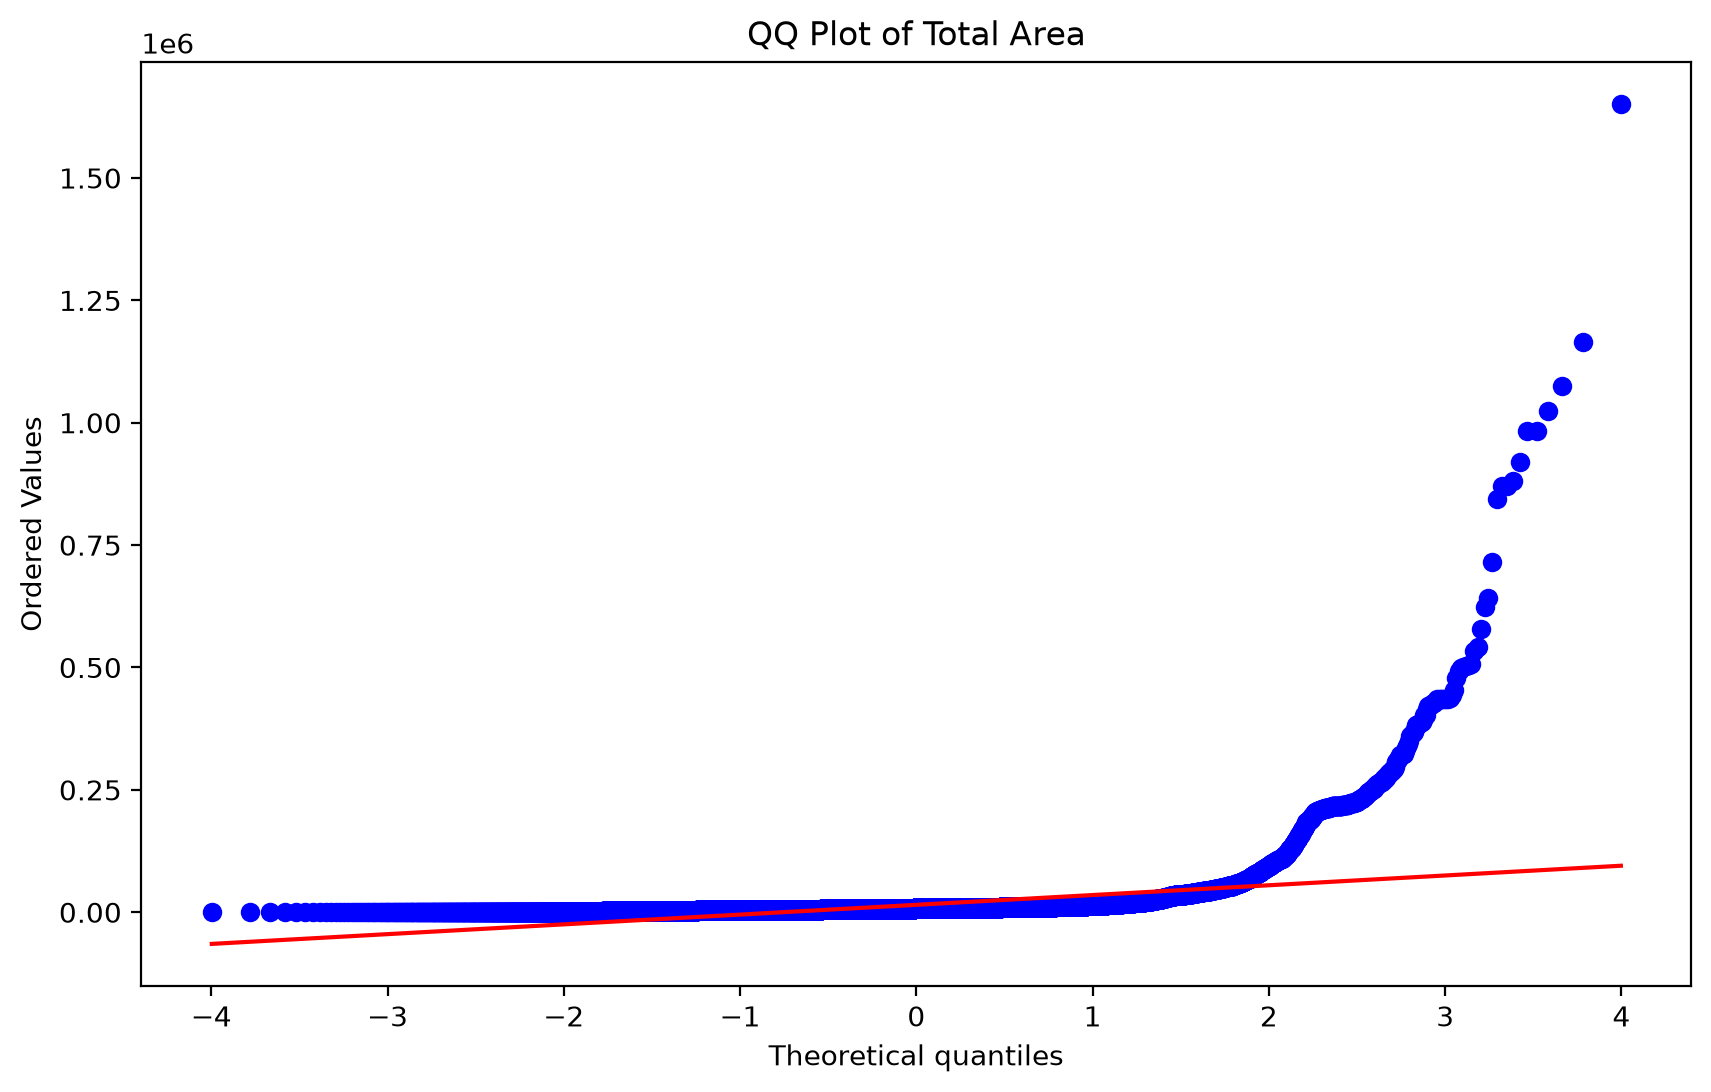

In [75]:
fig , ax = plt.subplots(figsize = (10,6))
stats.probplot(housing_data.sqft_lot, dist = 'norm', plot = ax)
plt.title('QQ Plot of Total Area')

In [19]:
housing_data.sqft_lot.describe()

count    2.161300e+04
mean     1.510697e+04
std      4.142051e+04
min      5.200000e+02
25%      5.040000e+03
50%      7.618000e+03
75%      1.068800e+04
max      1.651359e+06
Name: sqft_lot, dtype: float64

In [20]:
(housing_data.sqft_lot > .5e+06).sum()

np.int64(21)

**The data is highly right skewed and have outliers which we have to deal with**

In [21]:
# Floors 
housing_data.floors.value_counts()

floors
1.0    10680
2.0     8241
1.5     1910
3.0      613
2.5      161
3.5        8
Name: count, dtype: int64

**Its better to convert all 3.5 to 3**

In [22]:
# Waterfront
housing_data.waterfront.value_counts()

waterfront
0    21450
1      163
Name: count, dtype: int64

view
0    19489
2      963
3      510
1      332
4      319
Name: count, dtype: int64


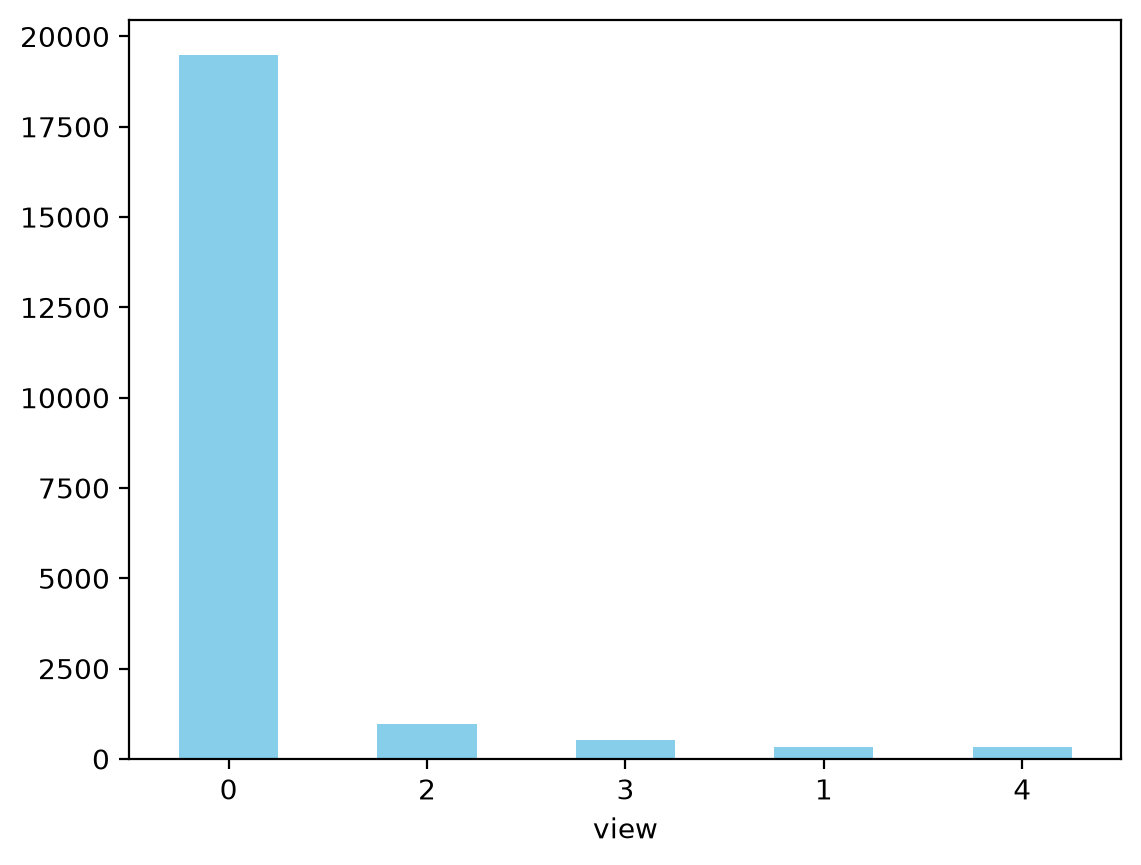

In [23]:
# View
view = housing_data.view.value_counts()
print(view)
view.plot(kind = 'bar', color = 'skyblue')
plt.xticks(rotation = 0);

condition
3    14031
4     5679
5     1701
2      172
1       30
Name: count, dtype: int64


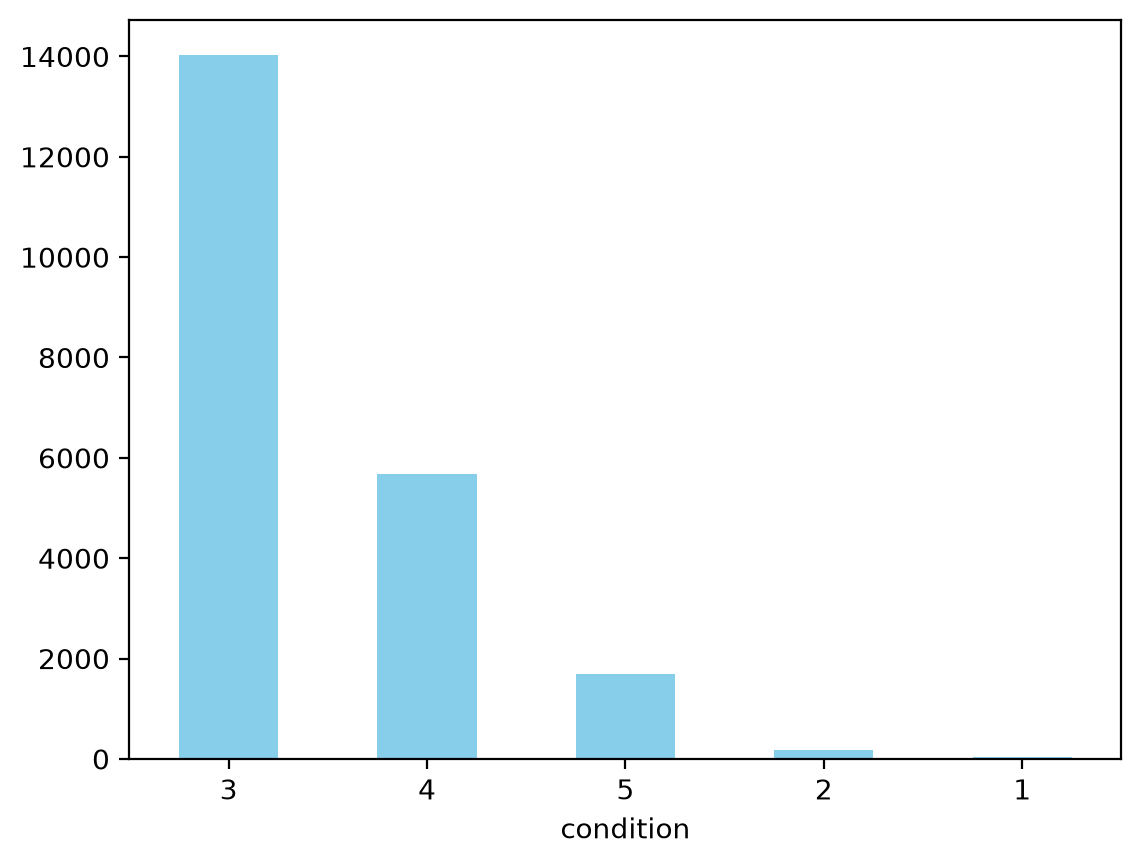

In [24]:
# Condition 
condition = housing_data.condition.value_counts()
print(condition)
condition.plot(kind = 'bar', color = 'skyblue')
plt.xticks(rotation = 0);

In [25]:
# Grade 
housing_data.grade.value_counts()

grade
7     8981
8     6068
9     2615
6     2038
10    1134
11     399
5      242
12      90
4       29
13      13
3        3
1        1
Name: count, dtype: int64

**We can use bucket for the grading**

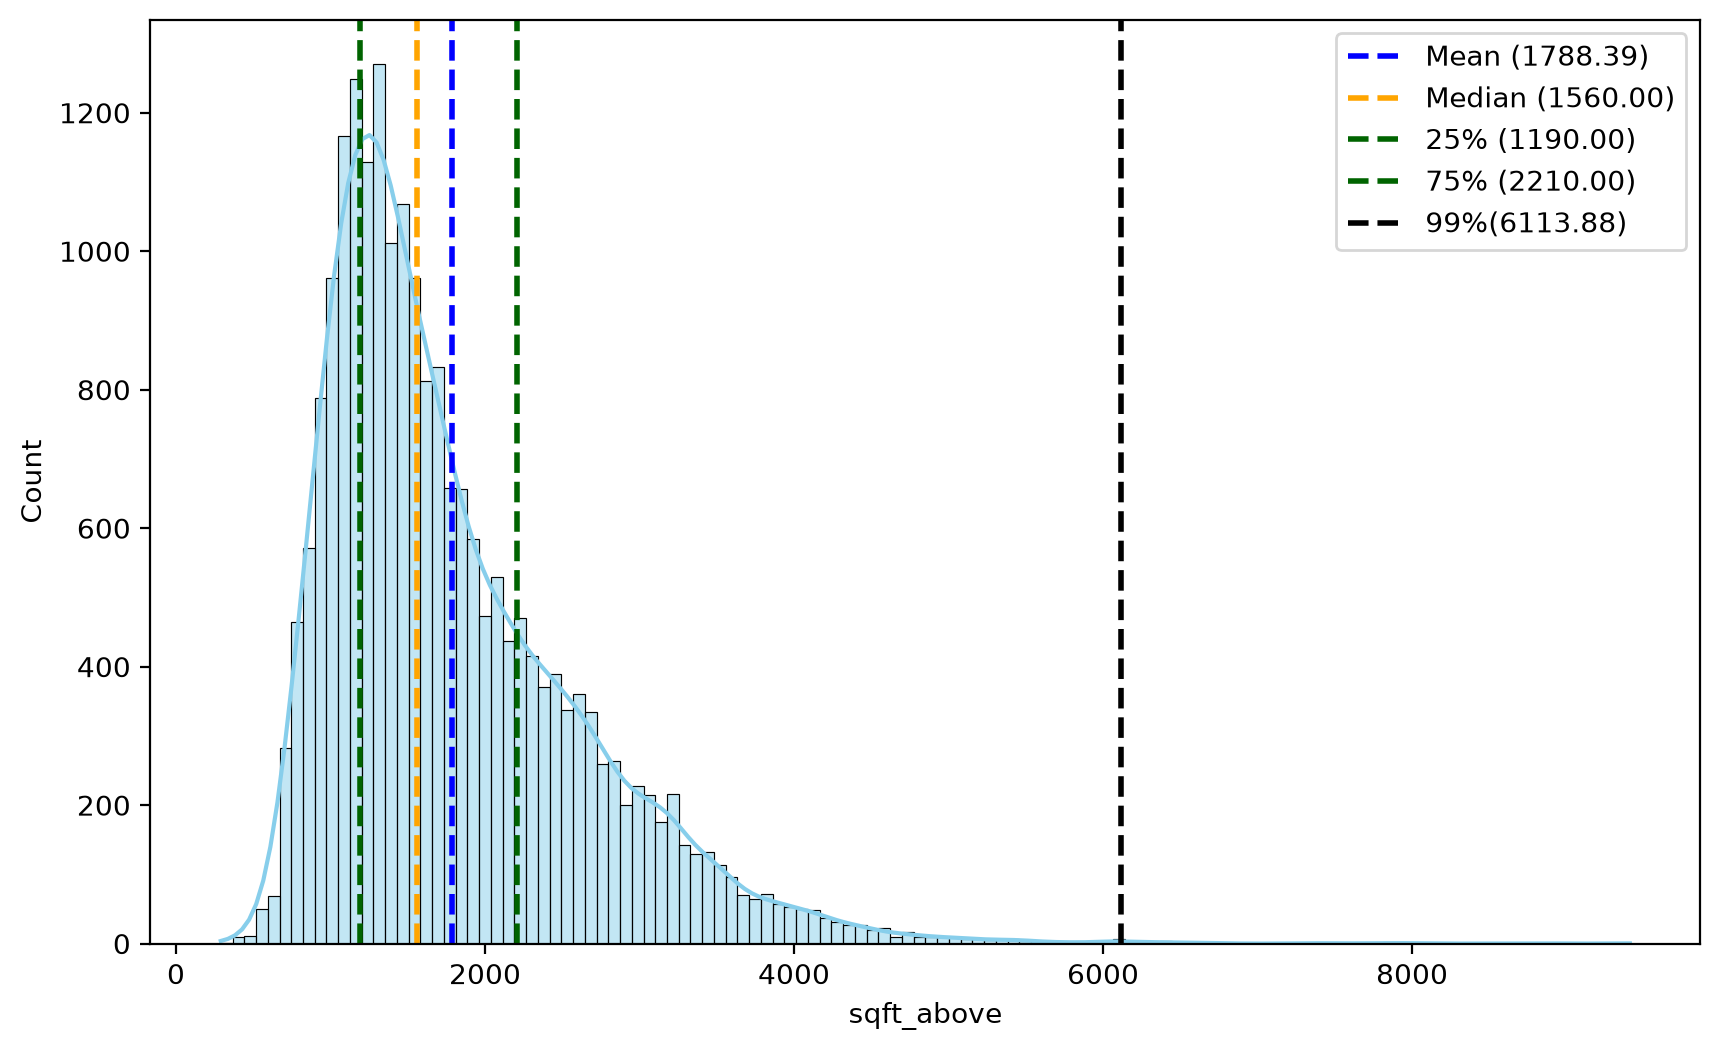

In [26]:
# Above Area
fig, ax = plt.subplots(figsize = (10,6))
sns.histplot(housing_data.sqft_above, kde = True, color = 'skyblue', bins = 120);

# complete statistics 
mean_val = housing_data.sqft_above.mean()
median_val = housing_data.sqft_above.median()
q25 = housing_data.sqft_above.quantile(0.25)
q75 = housing_data.sqft_above.quantile(0.75)
q99 = housing_data.sqft_above.quantile(0.999)

# draw vertical lines
ax.axvline(mean_val,color ='blue', linestyle = '--', linewidth = 2, label = f'Mean ({mean_val:.2f})')
ax.axvline(median_val, color = 'orange', linestyle = '--', linewidth = 2, label = f'Median ({median_val:.2f})')
ax.axvline(q25, color= 'darkgreen', linestyle = '--', linewidth = 2, label = f'25% ({q25:.2f})')
ax.axvline(q75, color= 'darkgreen', linestyle = '--', linewidth = 2, label = f'75% ({q75:.2f})')
ax.axvline(q99, color = 'black', linestyle = '--' , linewidth = 2, label = f'99%({q99:.2f})')
plt.legend();

Text(0.5, 1.0, 'QQ plot of Sqft Above')

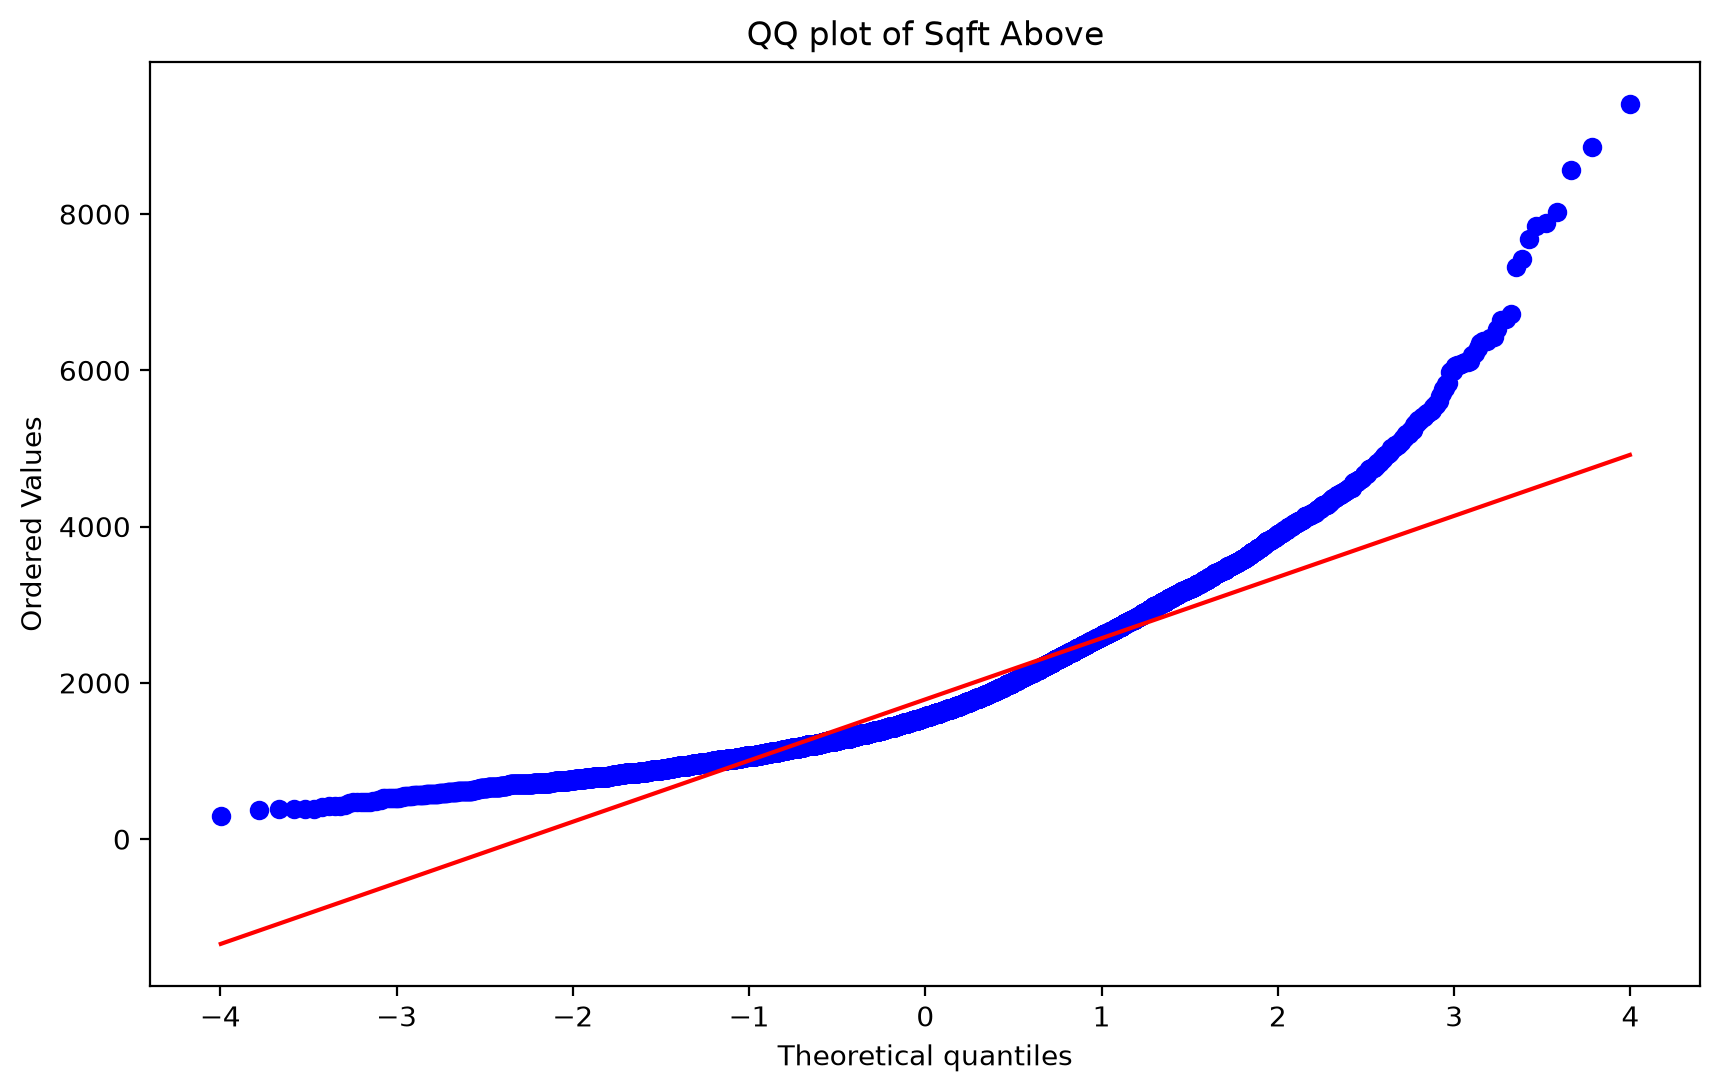

In [76]:
fig, ax = plt.subplots(figsize = (10,6))
stats.probplot(housing_data.sqft_above, dist = 'norm', plot = ax)
plt.title('QQ plot of Sqft Above')

**Right skewed this need to be normalized**\
If mean > median → right‑skewed.\
If mean < median → left‑skewed.

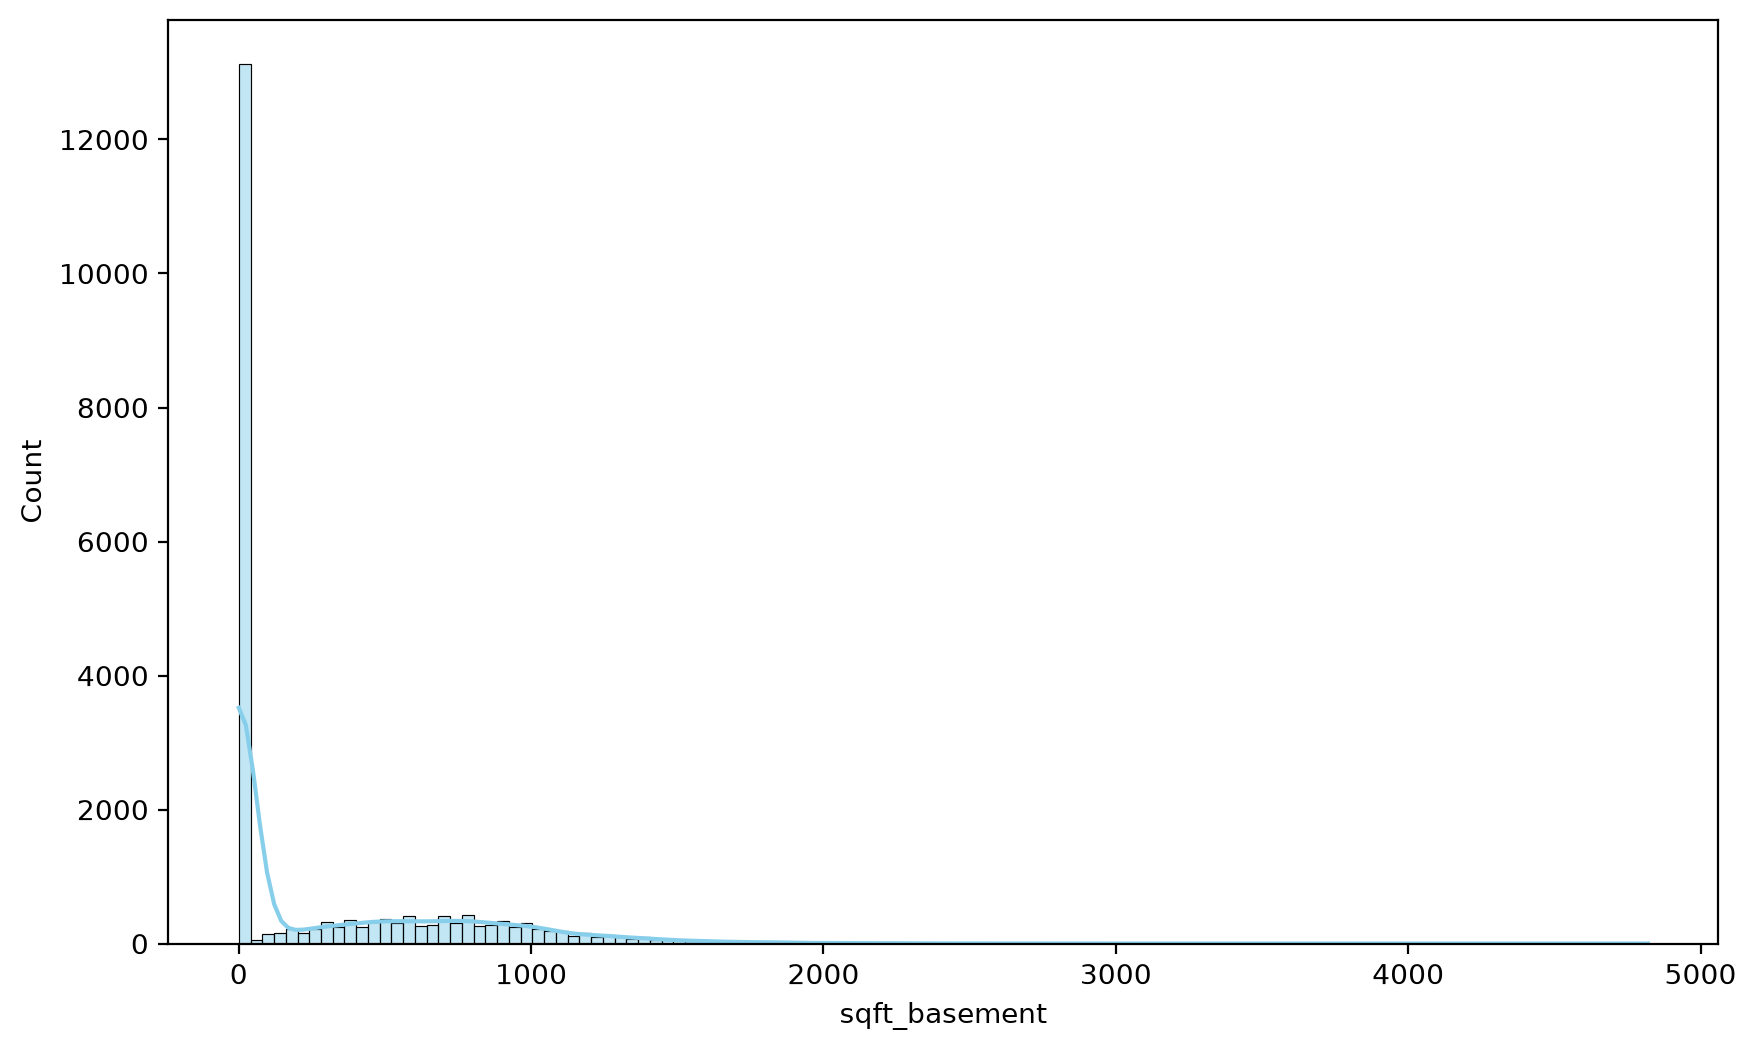

In [27]:
# Basement size
fig, ax = plt.subplots(figsize = (10,6))
sns.histplot(housing_data.sqft_basement, color = 'skyblue', kde = True);

In [28]:
housing_data.sqft_basement.describe()

count    21613.000000
mean       291.509045
std        442.575043
min          0.000000
25%          0.000000
50%          0.000000
75%        560.000000
max       4820.000000
Name: sqft_basement, dtype: float64

**Can keep it as it is which is easy but not so good idea just a waste of information what we can do ism make a new column for has basement or not and in place of 0 we will use NaN**

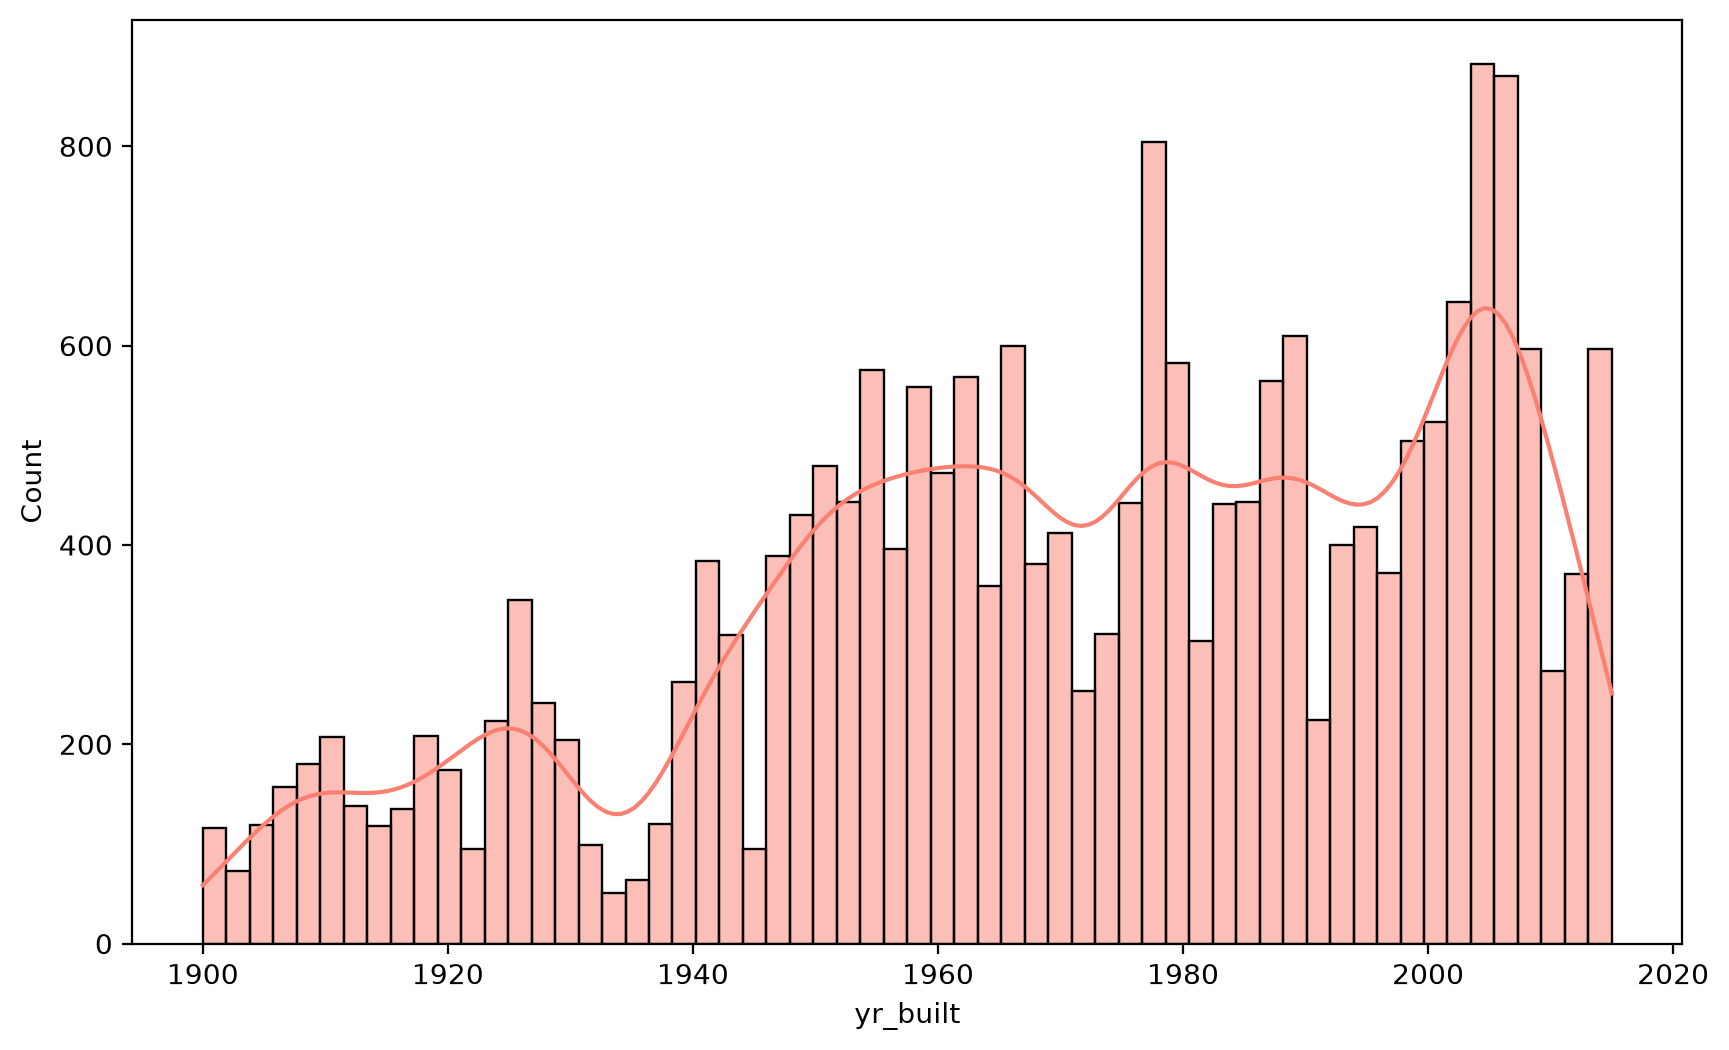

In [29]:
# Built year
fig, ax = plt.subplots(figsize = (10,6))
sns.histplot(housing_data.yr_built, kde = True, color = 'salmon', bins = 60);

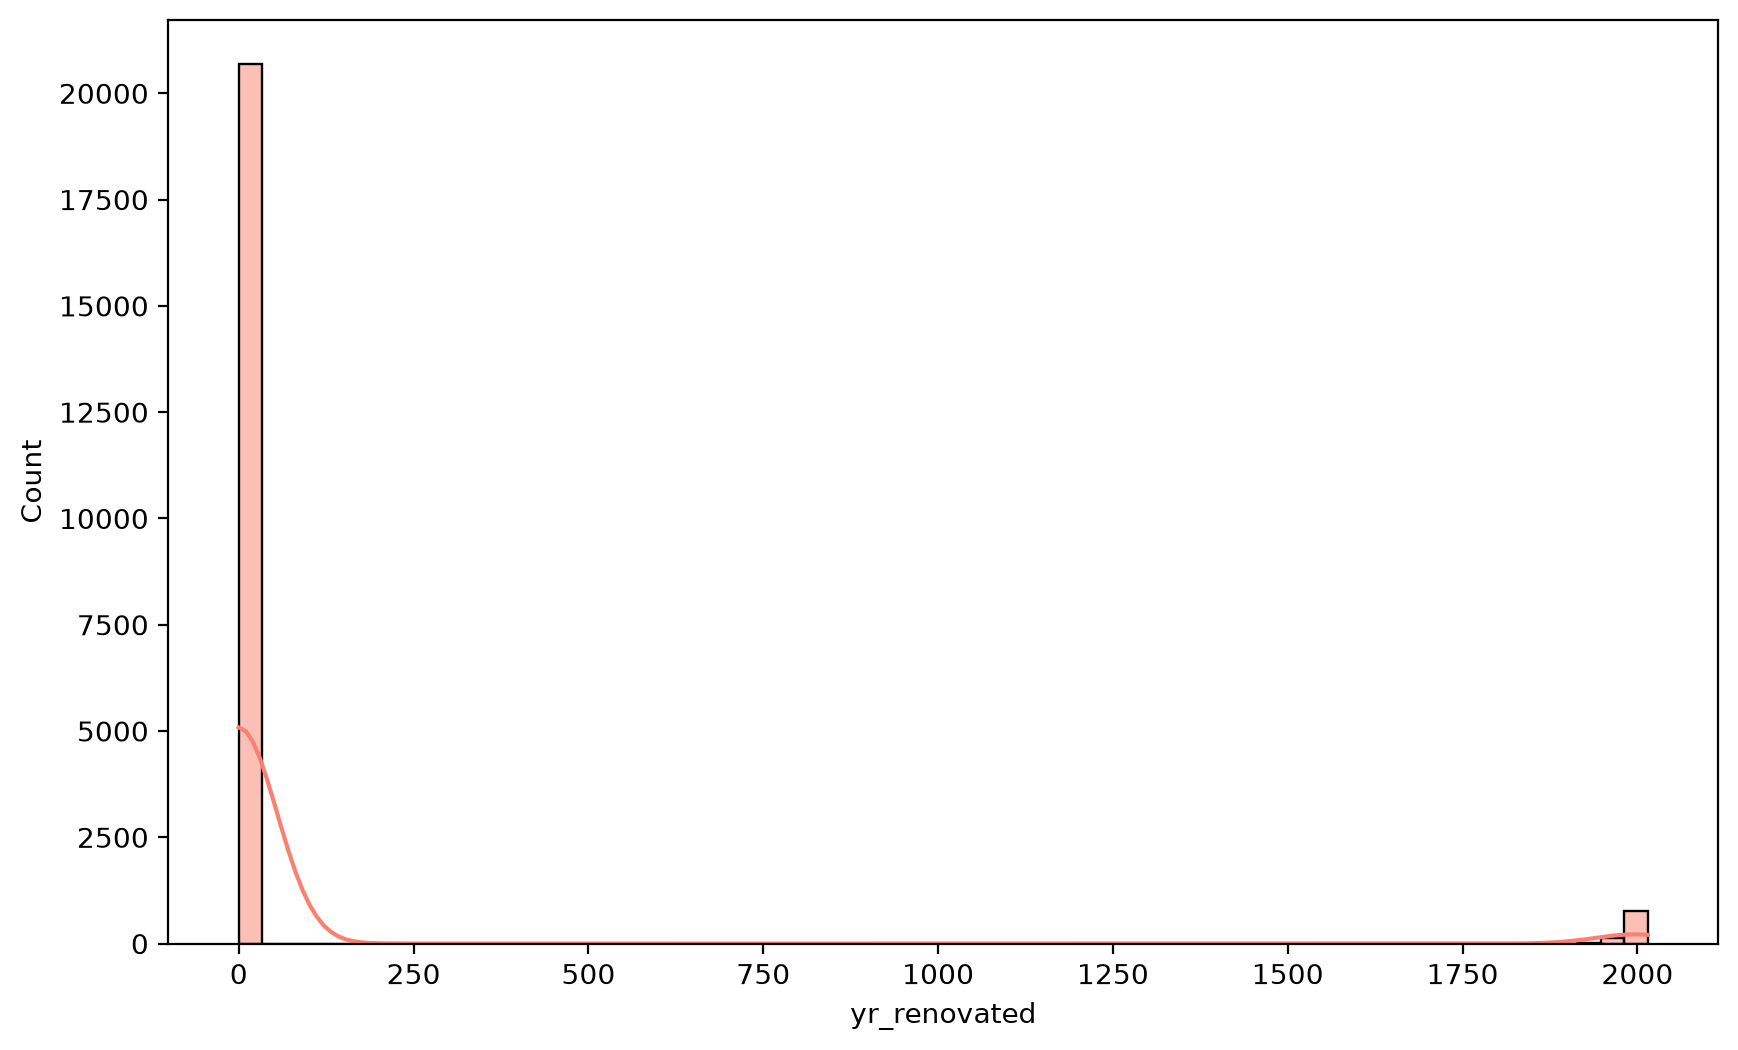

In [30]:
# Renovated yr 
fig, ax = plt.subplots(figsize = (10,6))
sns.histplot(housing_data.yr_renovated, kde = True, color = 'salmon', bins = 60);

**For this we ill create a new column which tells if it's renovated or not**

In [31]:
housing_data.zipcode.nunique()

70

**We will try with dropped zipcode and with zipcode**

###  3.2 Learning patterns between 2 or more columns

In [32]:
# Lat and Long ploting both together
# computing mean coordinates
mean_lat = housing_data.lat.mean()
mean_long  = housing_data.long.mean()

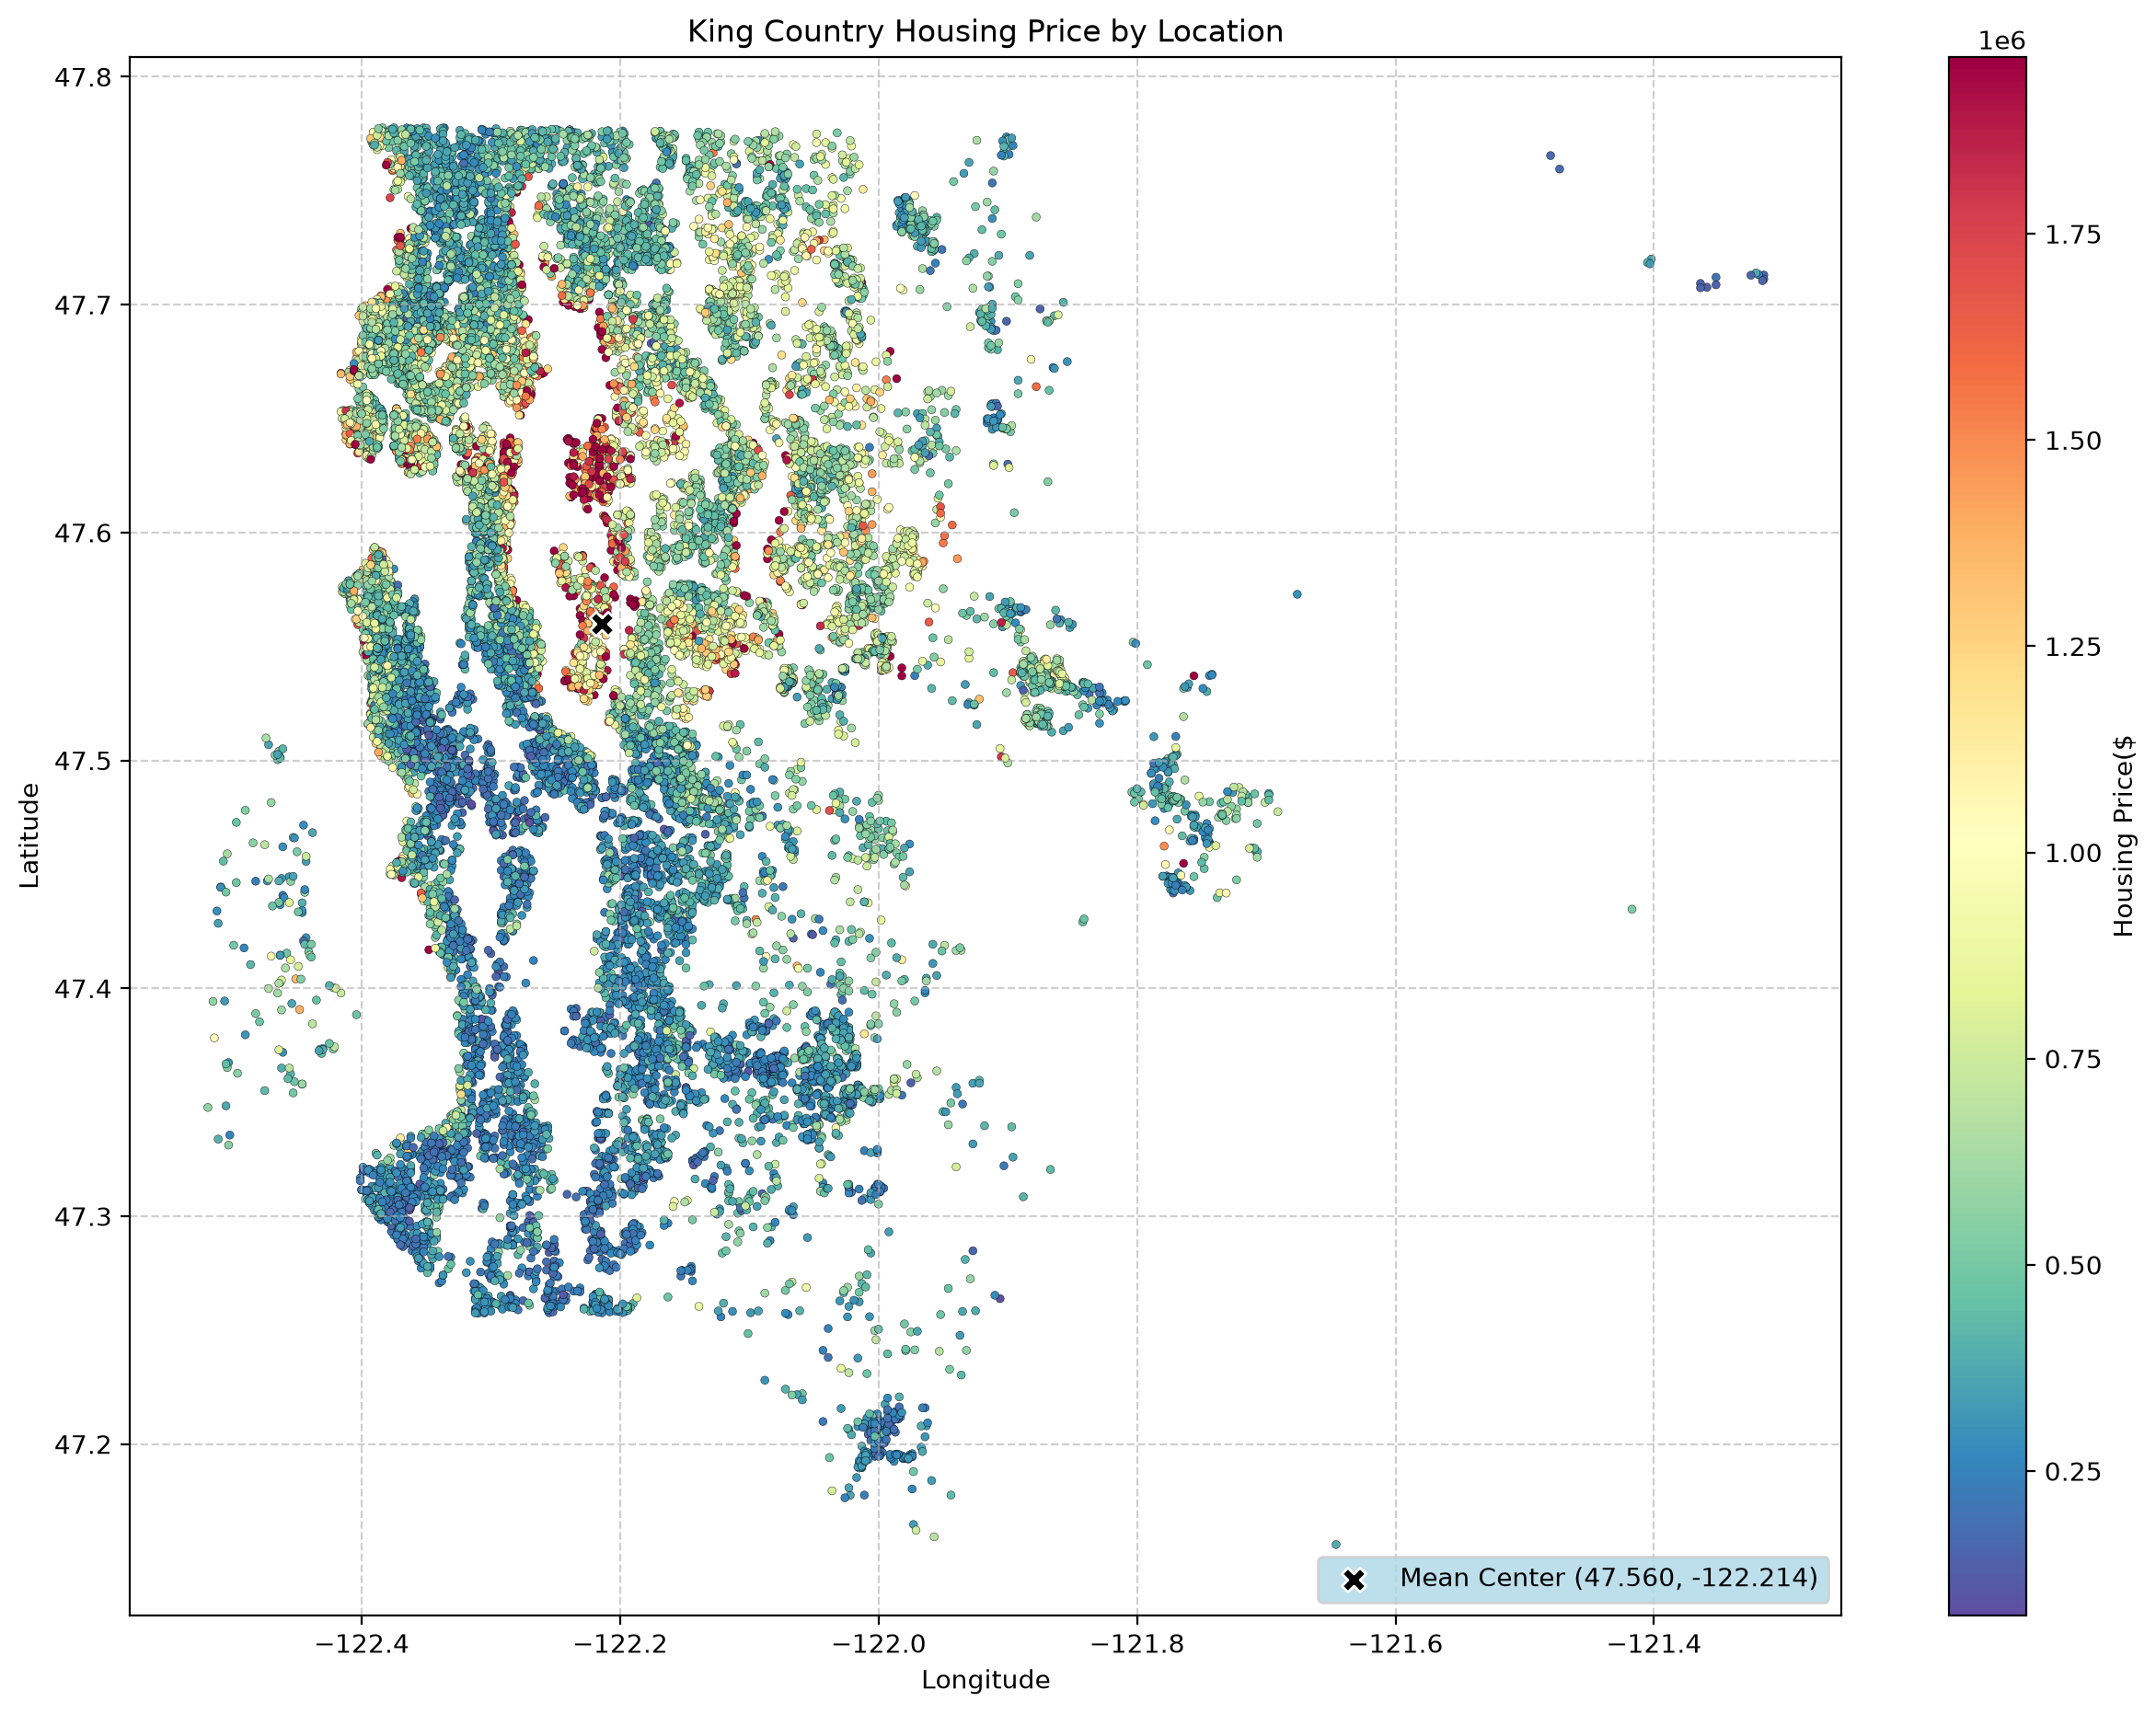

In [33]:
#plotting the location of houses
fig, ax = plt.subplots(figsize = (15,11))
scatter = ax.scatter(x = housing_data.long,
            y = housing_data.lat , 
            c = housing_data.price,
            cmap = 'Spectral_r',
            s= 10,
            edgecolors= 'black',
            linewidths= .15,
            alpha = 1,
            vmax = housing_data.price.quantile(0.99)
           )
# overlay mean marker 
ax.scatter(mean_long,
            mean_lat,
            color = 'black',
            marker = 'X',
            s = 90,
            zorder = 5,
            edgecolors = 'white',
            linewidths = 1,
            label = f'Mean Center ({mean_lat:.3f}, {mean_long:.3f})'
           )

# showing the plot 
plt.colorbar(scatter, ax = ax, label = 'Housing Price($')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('King Country Housing Price by Location')
plt.legend(loc= 'lower right', frameon = True, facecolor = 'lightblue')
plt.grid(True, linestyle = '--', alpha = .6)
plt.savefig('my_plot.svg', bbox_inches = 'tight')
plt.show()


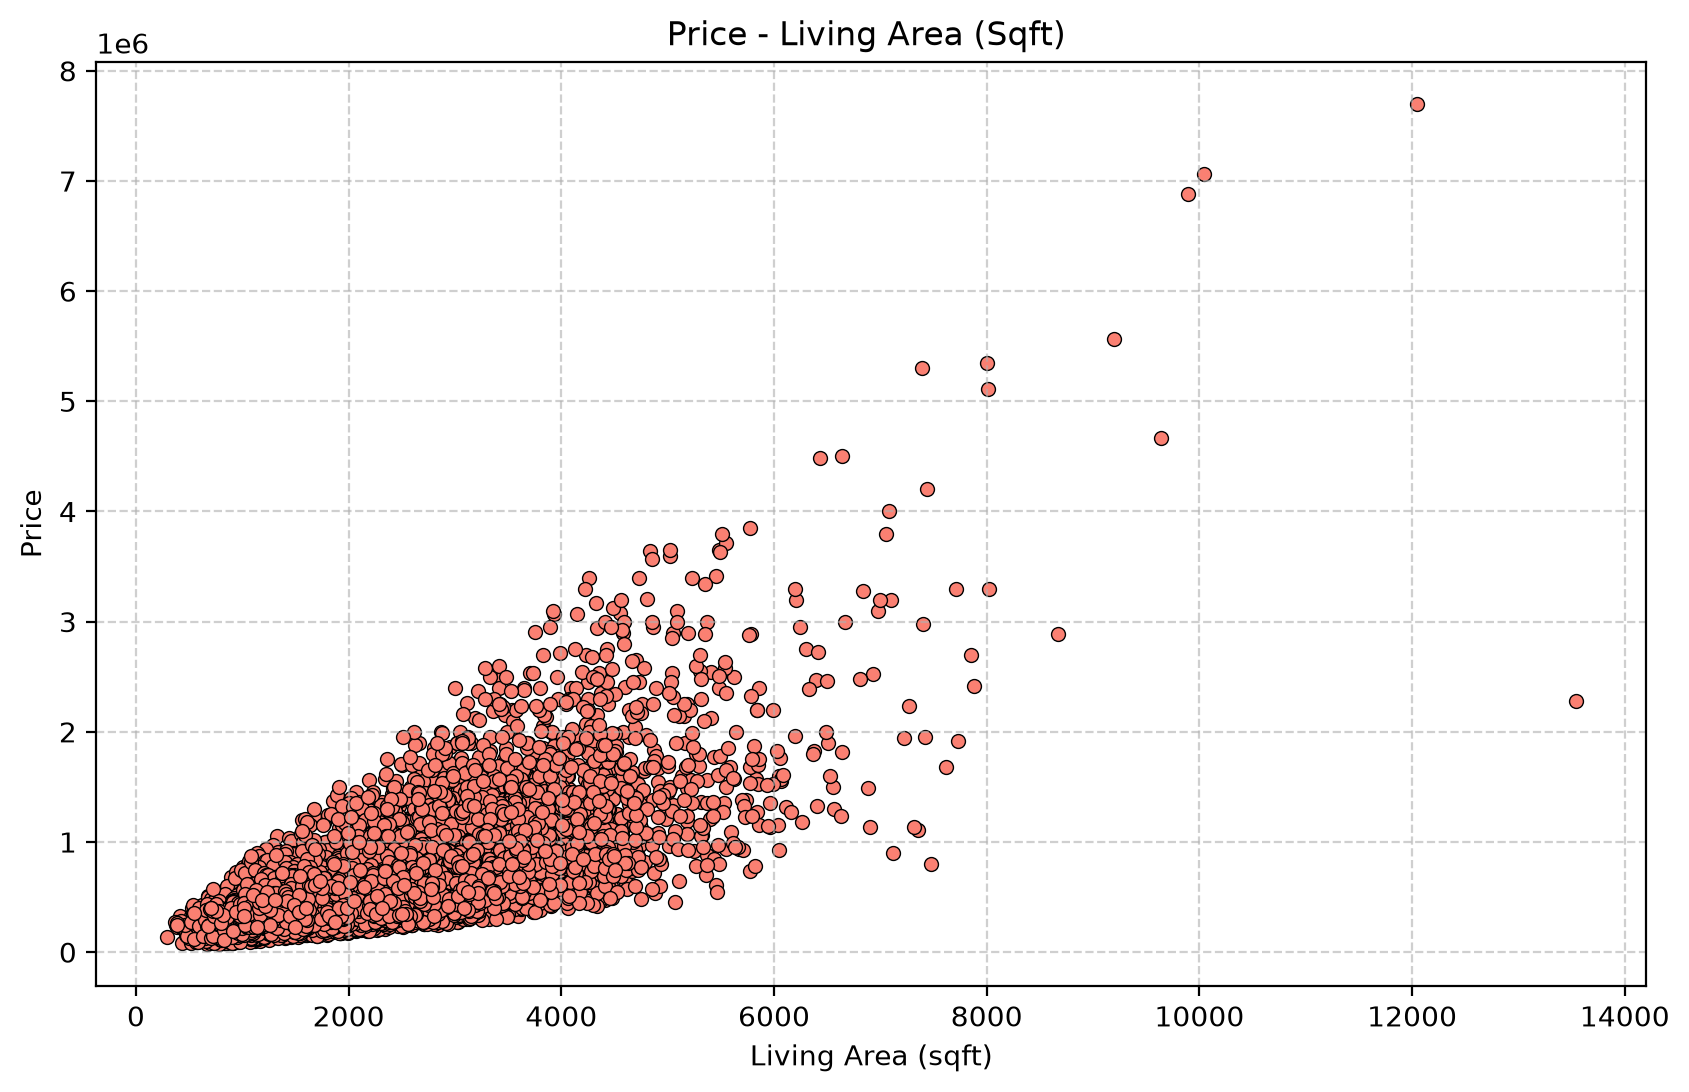

In [34]:
# Price - Living area
fig, ax = plt.subplots(figsize = (10,6))
plt.scatter(housing_data.sqft_living, 
            housing_data.price,
            color = 'salmon',
            s = 25, 
            edgecolors= 'black',
            linewidths= .5,
           )
plt.xlabel('Living Area (sqft)')
plt.ylabel('Price')
plt.title('Price - Living Area (Sqft) ')
plt.grid(True, alpha = .6, linestyle= '--')

plt.show()

**We can see there are some outliers that we have to deal with**

## 4.  Transforming the dataset

In [35]:
# dropping the zipcode
df = housing_data.drop('zipcode', axis = 1)

In [36]:
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,47.5112,-122.257
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,47.7210,-122.319
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,47.7379,-122.233
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,47.5208,-122.393
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,47.6168,-122.045
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,47.6993,-122.346
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,47.5107,-122.362
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,47.5944,-122.299
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,47.5345,-122.069


In [37]:
# Bedrooms

# deleting the extreme outlier
df = df[df.bedrooms != 33]

# bedrooms > 8 = 8
df.loc[df.bedrooms > 8, 'bedrooms'] = 8

# bathrooms > 6 = 6
df.loc[df.bathrooms> 6, 'bathrooms'] = 6

# bathrooms between 5 to 6 = 5
df.loc[(df.bathrooms > 5) & (df.bathrooms < 6), 'bathrooms'] = 5

# floors above 3 = 3
df.loc[df.floors > 3,'floors'] = 3


In [38]:
df.floors.value_counts()

floors
1.0    10679
2.0     8241
1.5     1910
3.0      621
2.5      161
Name: count, dtype: int64

In [39]:
# basement of not new column
df['has_basement'] = (df.sqft_basement > 0).astype(int)
df.loc[df.sqft_basement == 0 , 'sqft_basement'] = np.nan

# renovation 
df['has_renovated'] = (df.yr_renovated > 0).astype(int)

In [40]:
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,has_basement,has_renovated
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,NaN,1955,0,47.5112,-122.257,0,0
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400.0,1951,1991,47.7210,-122.319,1,1
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,NaN,1933,0,47.7379,-122.233,0,0
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910.0,1965,0,47.5208,-122.393,1,0
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,NaN,1987,0,47.6168,-122.045,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,NaN,2009,0,47.6993,-122.346,0,0
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,NaN,2014,0,47.5107,-122.362,0,0
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,NaN,2009,0,47.5944,-122.299,0,0
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,NaN,2004,0,47.5345,-122.069,0,0


In [41]:
df.to_csv('one.csv', index= False)